<a href="https://colab.research.google.com/github/SashaVeremchuk/Gazprom-production-forecast/blob/main/data_overview.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Обзор данных добычи месторождения Volve

Тетрадка для Google Colab: загружает Excel-файл с данными через `gdown` и делает первичный обзор
суточного и месячного листов.

## Подготовка в Colab

1. Откройте панель **Secrets** (значок ключа слева) и добавьте секрет `DATA_URL`.
2. Значение секрета — ссылка Google Drive на файл `data.xlsx` (доступ «всем, у кого есть ссылка») или просто ID файла.
3. Включите для тетрадки доступ к секрету (переключатель *Notebook access*).

При запуске вне Colab тетрадка читает локальный файл `data.xlsx` из папки `data`.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams["figure.figsize"] = (14, 5)
plt.rcParams["axes.grid"] = True

## Загрузка файла

In [ ]:
DATA_FILE = Path("data.xlsx")
SECRET_NAME = "DATA_URL"

try:
    from google.colab import userdata
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    import gdown

    data_url = (userdata.get(SECRET_NAME) or "").strip()
    if not data_url:
        raise ValueError(f"Секрет {SECRET_NAME} пуст: укажите ссылку Google Drive или ID файла.")

    if not DATA_FILE.exists():
        if data_url.startswith("http"):
            gdown.download(url=data_url, output=str(DATA_FILE), quiet=False, fuzzy=True)
        else:
            gdown.download(id=data_url, output=str(DATA_FILE), quiet=False)
else:
    # Локальный запуск: файл лежит рядом с тетрадкой, в папке data
    if not DATA_FILE.exists() and Path("data", DATA_FILE).exists():
        DATA_FILE = Path("data", DATA_FILE)

if not DATA_FILE.exists():
    raise FileNotFoundError(f"Файл {DATA_FILE.resolve()} не найден.")

print(f"Файл: {DATA_FILE.resolve()} ({DATA_FILE.stat().st_size / 1024**2:.1f} МБ)")

Файл: /content/data.xlsx (2.2 МБ)


## Чтение листов

In [ ]:
xls = pd.ExcelFile(DATA_FILE)
print("Листы:", xls.sheet_names)

DAILY_SHEET = "Daily Production Data"
MONTHLY_SHEET = "Monthly Production Data"
DESCR_SHEET = "Описание колонок"

daily_raw = pd.read_excel(xls, DAILY_SHEET)
monthly_raw = pd.read_excel(xls, MONTHLY_SHEET)
descr_raw = pd.read_excel(xls, DESCR_SHEET) if DESCR_SHEET in xls.sheet_names else None

for name, df in [(DAILY_SHEET, daily_raw), (MONTHLY_SHEET, monthly_raw)]:
    print(f"{name}: {df.shape[0]:,} строк × {df.shape[1]} колонок")

Листы: ['Daily Production Data', 'Monthly Production Data', 'Описание колонок']
Daily Production Data: 15,634 строк × 24 колонок
Monthly Production Data: 527 строк × 10 колонок


### Описание колонок

Лист с описанием содержит две таблицы подряд (месячные и суточные колонки), разделённые пустыми строками
и повторным заголовком. Собираем их в один справочник.

In [ ]:
if descr_raw is not None:
    descr = descr_raw.rename(columns=str.strip).dropna(how="all")
    descr = descr.apply(lambda s: s.str.strip() if s.dtype == object or pd.api.types.is_string_dtype(s) else s)
    header = descr.columns.tolist()
    descr = descr[descr[header[0]] != header[0]].reset_index(drop=True)
    descr["Лист"] = np.where(descr[header[0]].isin(monthly_raw.columns), MONTHLY_SHEET, DAILY_SHEET)
    col_info = descr.set_index(header[0])
    display(descr)
else:
    col_info = pd.DataFrame()
    print("Лист с описанием колонок отсутствует.")

,Исходная колонка,Русское название,Единица,Описание,Лист
0,Wellbore name,Название ствола скважины,—,Идентификатор ствола.,Monthly Production Data
1,NPDCode,Код ствола в NPD,—,Числовой идентификатор NPD.,Monthly Production Data
2,Year,Год,—,Год производственного отчёта.,Monthly Production Data
3,Month,Месяц,—,Номер календарного месяца.,Monthly Production Data
4,On Stream,Время работы за месяц,ч,Суммарное время работы скважины в соответствую...,Monthly Production Data
5,Oil,Месячная добыча нефти,ст. м³,Добыча нефти за месяц.,Monthly Production Data
6,Gas,Месячная добыча газа,ст. м³,Добыча газа за месяц.,Monthly Production Data
7,Water,Месячная добыча воды,ст. м³,Попутно добытая вода за месяц.,Monthly Production Data
8,GI,Месячная закачка газа,ст. м³,Месячная закачка газа,Monthly Production Data
9,WI,Месячная закачка воды,ст. м³,Месячная закачка воды,Monthly Production Data


## Суточные данные

### Структура и пропуски

In [ ]:
daily = daily_raw.copy()
daily["DATEPRD"] = pd.to_datetime(daily["DATEPRD"])
daily = daily.sort_values(["NPD_WELL_BORE_NAME", "DATEPRD"]).reset_index(drop=True)

overview = pd.DataFrame({
    "dtype": daily.dtypes.astype(str),
    "непустых": daily.notna().sum(),
    "пропусков, %": daily.isna().mean() * 100,
    "уникальных": daily.nunique(),
})
if not col_info.empty:
    overview = overview.join(col_info[["Русское название", "Единица"]])
overview

,dtype,непустых,"пропусков, %",уникальных,Русское название,Единица
DATEPRD,datetime64[ns],15634,0.00,3327,Дата добычи,—
WELL_BORE_CODE,object,15634,0.00,7,Код ствола скважины,—
NPD_WELL_BORE_CODE,int64,15634,0.00,7,Код ствола в NPD,—
NPD_WELL_BORE_NAME,object,15634,0.00,7,Название ствола в NPD,—
NPD_FIELD_CODE,int64,15634,0.00,1,Код месторождения в NPD,—
NPD_FIELD_NAME,object,15634,0.00,1,Название месторождения,—
NPD_FACILITY_CODE,int64,15634,0.00,1,Код производственного объекта,—
NPD_FACILITY_NAME,object,15634,0.00,1,Название производственного объекта,—
ON_STREAM_HRS,float64,15349,1.82,925,Время работы за сутки,ч
AVG_DOWNHOLE_PRESSURE,float64,8980,42.56,6567,Среднее забойное давление,бар


In [ ]:
daily.head()

,DATEPRD,WELL_BORE_CODE,NPD_WELL_BORE_CODE,NPD_WELL_BORE_NAME,NPD_FIELD_CODE,NPD_FIELD_NAME,NPD_FACILITY_CODE,NPD_FACILITY_NAME,ON_STREAM_HRS,AVG_DOWNHOLE_PRESSURE,AVG_DOWNHOLE_TEMPERATURE,AVG_DP_TUBING,AVG_ANNULUS_PRESS,AVG_CHOKE_SIZE_P,AVG_CHOKE_UOM,AVG_WHP_P,AVG_WHT_P,DP_CHOKE_SIZE,BORE_OIL_VOL,BORE_GAS_VOL,BORE_WAT_VOL,BORE_WI_VOL,FLOW_KIND,WELL_TYPE
0,2014-04-07,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.00,0.00,0.00,0.00,0.00,0.00,%,0.00,0.00,0.00,0.00,0.00,0.00,NaN,production,WI
1,2014-04-08,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.00,NaN,NaN,NaN,0.00,1.00,%,0.00,0.00,0.00,0.00,0.00,0.00,NaN,production,OP
2,2014-04-09,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.00,NaN,NaN,NaN,0.00,0.98,%,0.00,0.00,0.00,0.00,0.00,0.00,NaN,production,OP
3,2014-04-10,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.00,NaN,NaN,NaN,0.00,0.55,%,0.00,0.00,0.00,0.00,0.00,0.00,NaN,production,OP
4,2014-04-11,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.00,310.38,96.88,277.28,0.00,1.22,%,33.10,10.48,33.07,0.00,0.00,0.00,NaN,production,OP


Константные колонки (одно значение на весь набор) — кандидаты на удаление:

In [ ]:
constant_cols = [c for c in daily.columns if daily[c].nunique(dropna=False) == 1]
daily[constant_cols].iloc[0] if constant_cols else "нет"

,0
NPD_FIELD_CODE,3420717
NPD_FIELD_NAME,VOLVE
NPD_FACILITY_CODE,369304
NPD_FACILITY_NAME,MÆRSK INSPIRER


In [ ]:
NUM_COLS = daily.select_dtypes("number").columns.difference(
    ["NPD_WELL_BORE_CODE", "NPD_FIELD_CODE", "NPD_FACILITY_CODE"]
).tolist()
daily[NUM_COLS].describe().T

,count,mean,std,min,25%,50%,75%,max
AVG_ANNULUS_PRESS,"7,890.00",14.86,8.41,0.00,10.84,16.31,21.31,30.02
AVG_CHOKE_SIZE_P,"8,919.00",55.17,36.69,0.00,18.95,52.10,99.92,100.00
AVG_DOWNHOLE_PRESSURE,"8,980.00",181.80,109.71,0.00,0.00,232.90,255.40,397.59
AVG_DOWNHOLE_TEMPERATURE,"8,980.00",77.16,45.66,0.00,0.00,103.19,106.28,108.50
AVG_DP_TUBING,"8,980.00",154.03,76.75,0.00,83.67,175.59,204.32,345.91
AVG_WHP_P,"9,155.00",45.38,24.75,0.00,31.15,37.93,57.10,137.31
AVG_WHT_P,"9,146.00",67.73,27.72,0.00,56.58,80.07,88.06,93.51
BORE_GAS_VOL,"9,161.00","161,049.06","188,136.41",0.00,"29,430.59","87,749.66","202,482.30","851,131.52"
BORE_OIL_VOL,"9,161.00","1,095.63","1,323.54",0.00,190.69,557.55,"1,345.20","5,901.84"
BORE_WAT_VOL,"9,161.00","1,672.15","1,706.98",-457.84,19.87,"1,097.79","3,260.95","8,019.74"


### Скважины: периоды работы, тип и вид операции

In [ ]:
wells = daily.groupby("NPD_WELL_BORE_NAME").agg(
    записей=("DATEPRD", "size"),
    начало=("DATEPRD", "min"),
    конец=("DATEPRD", "max"),
    тип=("WELL_TYPE", lambda s: ", ".join(sorted(s.unique()))),
    операция=("FLOW_KIND", lambda s: ", ".join(sorted(s.unique()))),
    нефть_ст_м3=("BORE_OIL_VOL", "sum"),
    газ_ст_м3=("BORE_GAS_VOL", "sum"),
    вода_ст_м3=("BORE_WAT_VOL", "sum"),
    закачка_воды_ст_м3=("BORE_WI_VOL", "sum"),
)
wells["дней_в_периоде"] = (wells["конец"] - wells["начало"]).dt.days + 1
wells["пропущено_дат"] = wells["дней_в_периоде"] - wells["записей"]

# Постоянный цвет для каждой скважины на всех графиках
WELL_COLORS = dict(zip(wells.index, plt.cm.tab10.colors))
wells

,записей,начало,конец,тип,операция,нефть_ст_м3,газ_ст_м3,вода_ст_м3,закачка_воды_ст_м3,дней_в_периоде,пропущено_дат
NPD_WELL_BORE_NAME,,,,,,,,,,,
15/9-F-1 C,746,2014-04-07,2016-04-21,"OP, WI",production,"177,709.33","26,440,918.60","207,302.39",0.00,746,0
15/9-F-11,1165,2013-07-08,2016-09-17,OP,production,"1,147,849.10","174,310,520.61","1,090,806.27",0.00,1168,3
15/9-F-12,3056,2008-02-12,2016-09-17,OP,production,"4,579,609.55","667,542,278.02","6,833,320.37",0.00,3141,85
15/9-F-14,3056,2008-02-12,2016-09-17,OP,production,"3,942,233.39","578,009,542.02","7,121,249.74",0.00,3141,85
15/9-F-15 D,978,2014-01-12,2016-09-17,OP,production,"148,518.56","22,505,350.95","52,366.40",0.00,980,2
15/9-F-4,3327,2007-09-01,2016-12-01,WI,injection,0.00,0.00,0.00,"16,240,727.04",3380,53
15/9-F-5,3306,2007-09-01,2016-09-18,"OP, WI","injection, production","41,160.68","6,561,825.74","13,533.18","14,089,406.49",3306,0


In [ ]:
pd.crosstab(daily["NPD_WELL_BORE_NAME"], [daily["FLOW_KIND"], daily["WELL_TYPE"]])

FLOW_KIND          injection production    
WELL_TYPE                 WI         OP  WI
NPD_WELL_BORE_NAME                         
15/9-F-1 C                 0        744   2
15/9-F-11                  0       1165   0
15/9-F-12                  0       3056   0
15/9-F-14                  0       3056   0
15/9-F-15 D                0        978   0
15/9-F-4                3327          0   0
15/9-F-5                3146        144  16

### Карта пропусков по скважинам (доля пропусков в колонке, %)

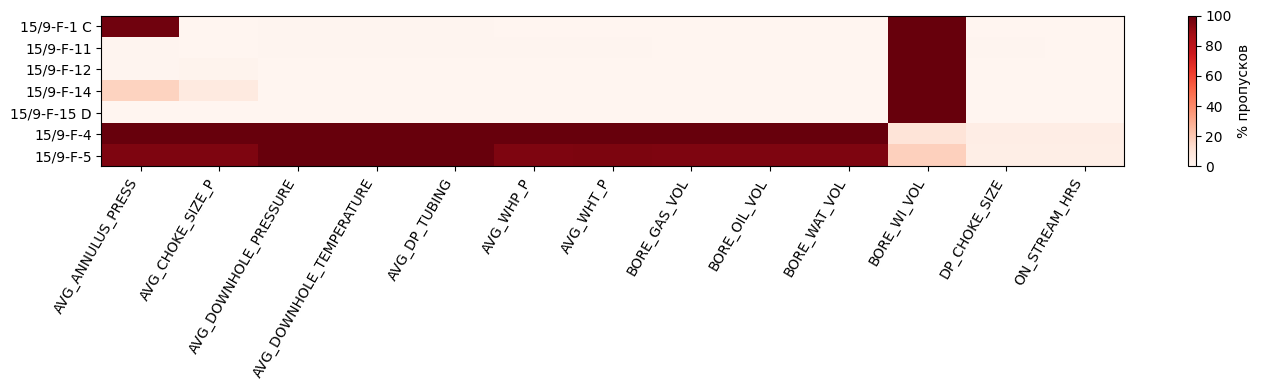

In [ ]:
na_by_well = daily.groupby("NPD_WELL_BORE_NAME")[NUM_COLS].agg(lambda s: s.isna().mean() * 100)

fig, ax = plt.subplots(figsize=(14, 4))
im = ax.imshow(na_by_well.values, aspect="auto", cmap="Reds", vmin=0, vmax=100)
ax.set_xticks(range(len(NUM_COLS)), NUM_COLS, rotation=60, ha="right")
ax.set_yticks(range(len(na_by_well)), na_by_well.index)
ax.grid(False)
fig.colorbar(im, ax=ax, label="% пропусков")
plt.tight_layout()
plt.show()

### Проверки качества

In [ ]:
checks = {
    "дубликаты (скважина, дата)": daily.duplicated(["NPD_WELL_BORE_NAME", "DATEPRD"]).sum(),
    "ON_STREAM_HRS > 24": (daily["ON_STREAM_HRS"] > 24).sum(),
    "ON_STREAM_HRS < 0": (daily["ON_STREAM_HRS"] < 0).sum(),
    "отрицательные объёмы": (daily[["BORE_OIL_VOL", "BORE_GAS_VOL", "BORE_WAT_VOL", "BORE_WI_VOL"]] < 0).sum().sum(),
    "добыча при ON_STREAM_HRS = 0": ((daily["ON_STREAM_HRS"] == 0) & (daily["BORE_OIL_VOL"] > 0)).sum(),
    "давление на забое = 0": (daily["AVG_DOWNHOLE_PRESSURE"] == 0).sum(),
    "отрицательные давления/перепады": (
        daily[["AVG_DOWNHOLE_PRESSURE", "AVG_DP_TUBING", "AVG_ANNULUS_PRESS", "AVG_WHP_P", "DP_CHOKE_SIZE"]] < 0
    ).sum().sum(),
}
pd.Series(checks, name="строк").to_frame()

,строк
"дубликаты (скважина, дата)",0
ON_STREAM_HRS > 24,20
ON_STREAM_HRS < 0,0
отрицательные объёмы,4
добыча при ON_STREAM_HRS = 0,1
давление на забое = 0,2312
отрицательные давления/перепады,0


### Суточная добыча и закачка по скважинам

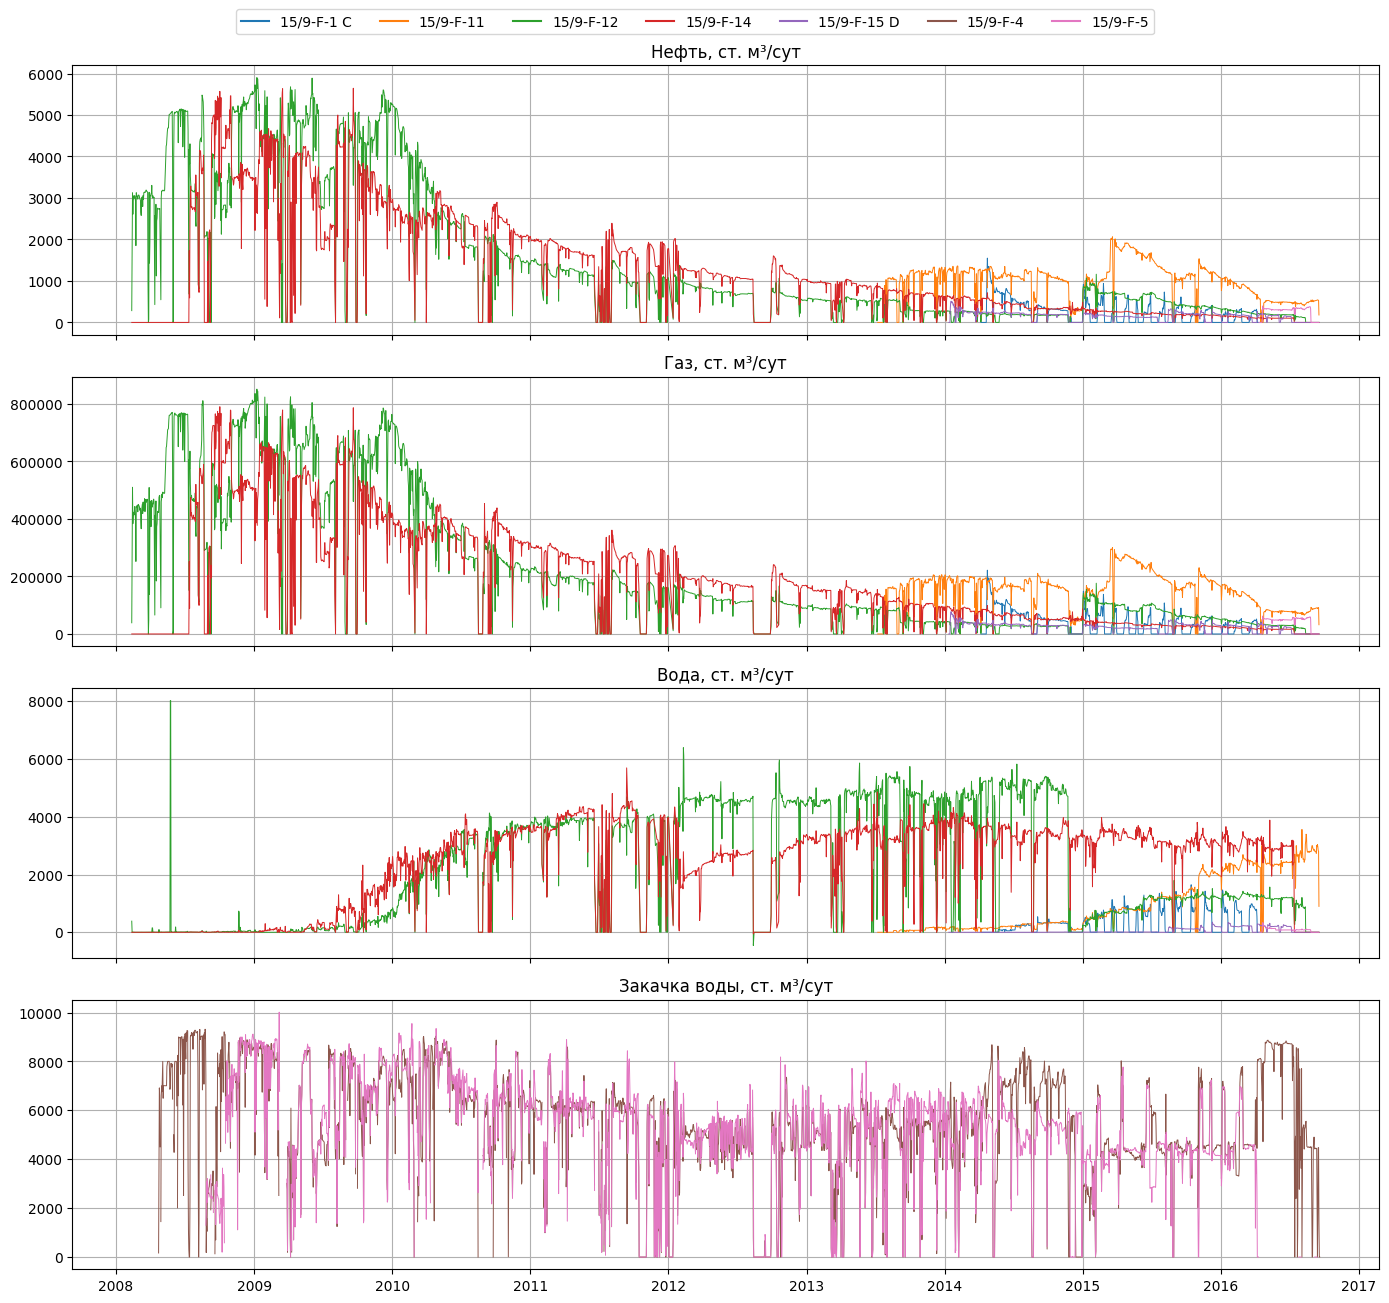

In [ ]:
series = [
    ("BORE_OIL_VOL", "Нефть, ст. м³/сут"),
    ("BORE_GAS_VOL", "Газ, ст. м³/сут"),
    ("BORE_WAT_VOL", "Вода, ст. м³/сут"),
    ("BORE_WI_VOL", "Закачка воды, ст. м³/сут"),
]

fig, axes = plt.subplots(len(series), 1, figsize=(14, 3.2 * len(series)), sharex=True)
for ax, (col, title) in zip(axes, series):
    for well, g in daily.groupby("NPD_WELL_BORE_NAME"):
        if g[col].fillna(0).abs().sum() > 0:
            ax.plot(g["DATEPRD"], g[col], lw=0.7, color=WELL_COLORS[well], label=well)
    ax.set_title(title)
fig.legend(handles=[plt.Line2D([], [], color=c, label=w) for w, c in WELL_COLORS.items()],
           ncol=len(WELL_COLORS), loc="upper center", bbox_to_anchor=(0.5, 1.02))
plt.tight_layout()
plt.show()

### Давления, температуры и штуцер по скважинам

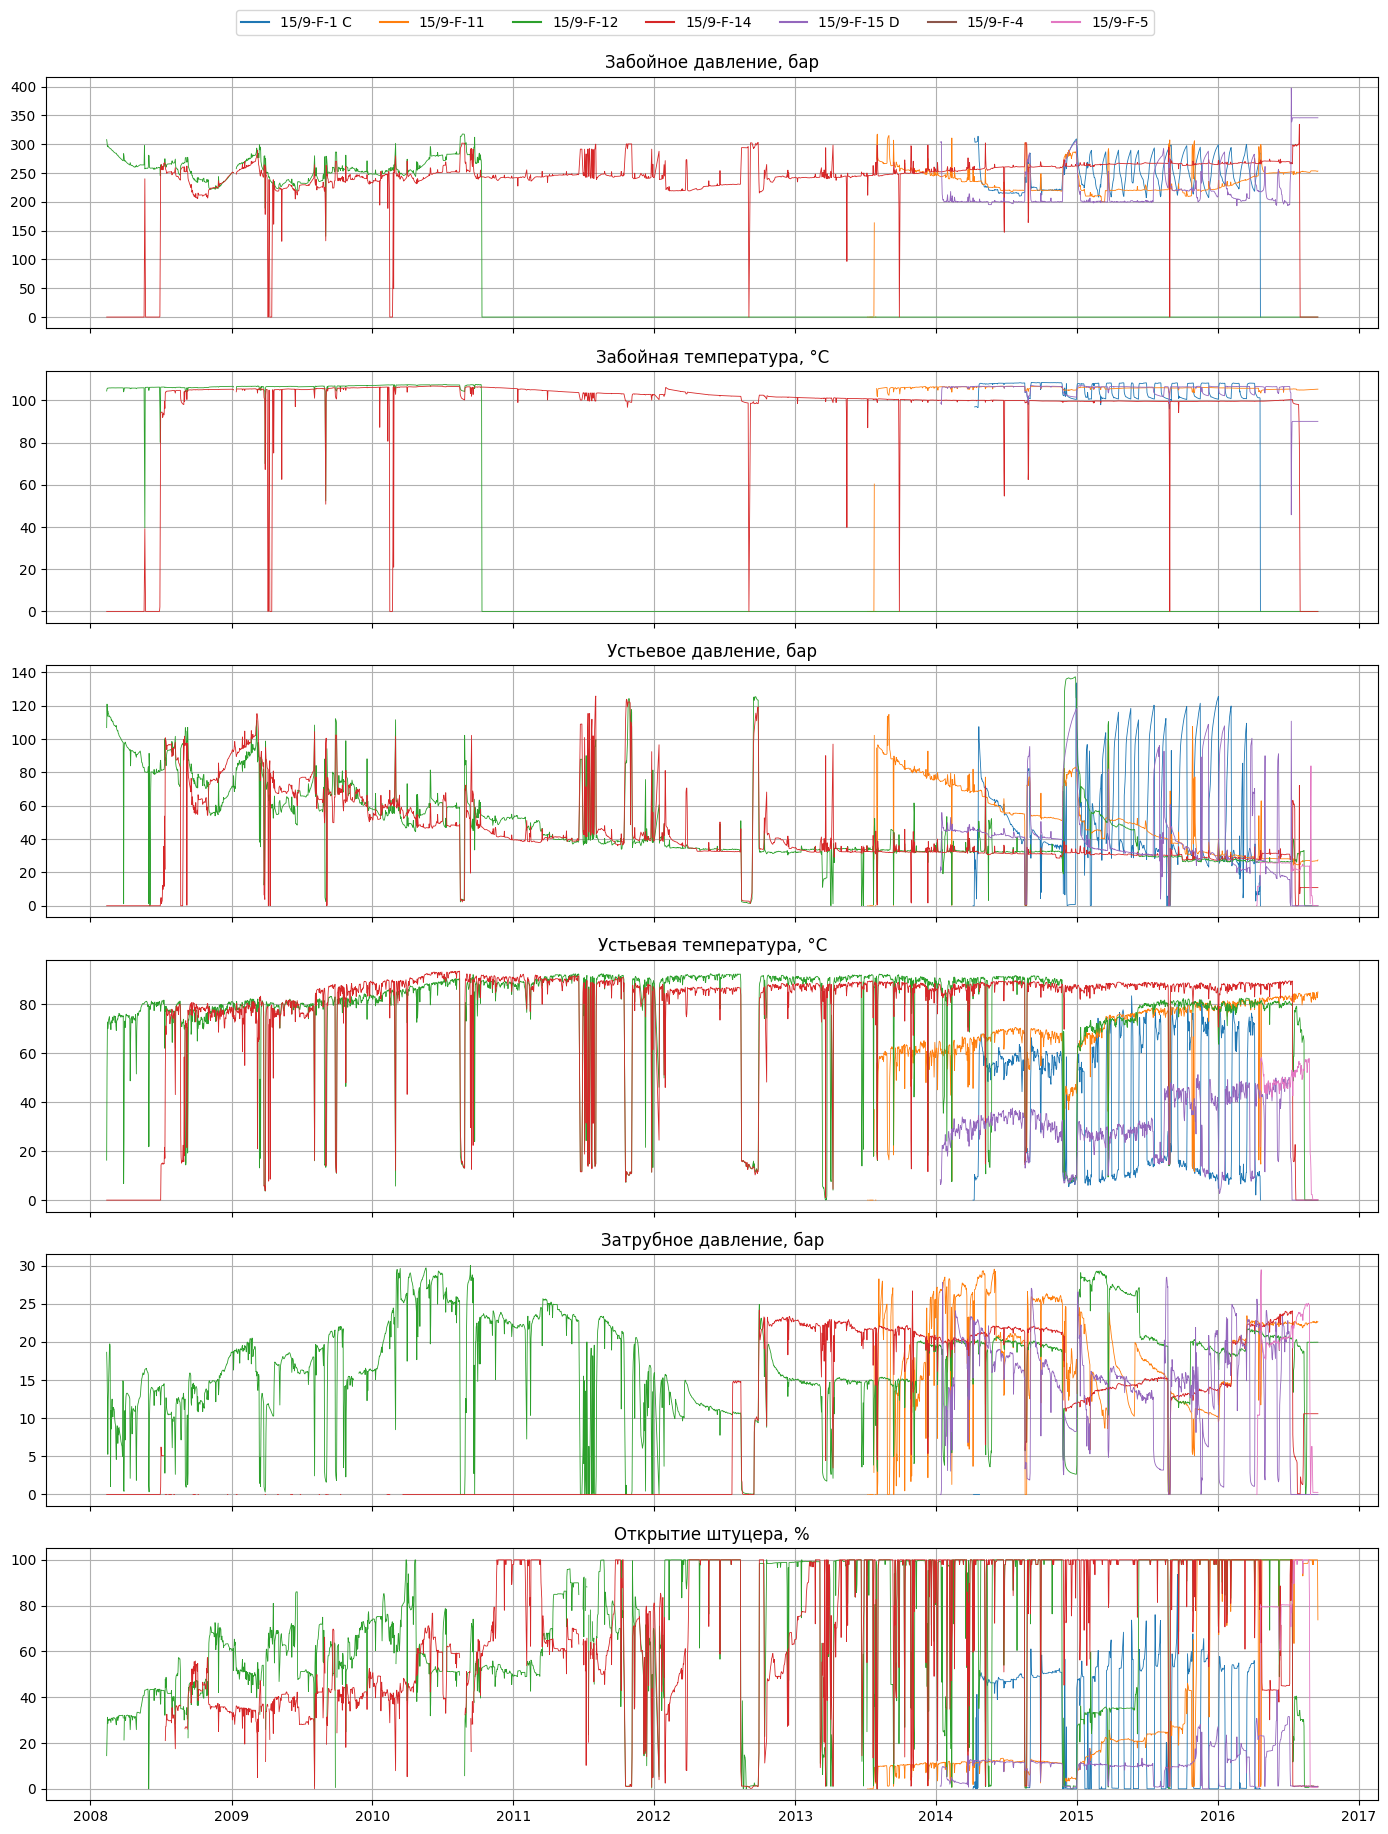

In [ ]:
params = [
    ("AVG_DOWNHOLE_PRESSURE", "Забойное давление, бар"),
    ("AVG_DOWNHOLE_TEMPERATURE", "Забойная температура, °C"),
    ("AVG_WHP_P", "Устьевое давление, бар"),
    ("AVG_WHT_P", "Устьевая температура, °C"),
    ("AVG_ANNULUS_PRESS", "Затрубное давление, бар"),
    ("AVG_CHOKE_SIZE_P", "Открытие штуцера, %"),
]

fig, axes = plt.subplots(len(params), 1, figsize=(14, 3 * len(params)), sharex=True)
for ax, (col, title) in zip(axes, params):
    for well, g in daily.groupby("NPD_WELL_BORE_NAME"):
        ax.plot(g["DATEPRD"], g[col], lw=0.6, color=WELL_COLORS[well], label=well)
    ax.set_title(title)
fig.legend(handles=[plt.Line2D([], [], color=c, label=w) for w, c in WELL_COLORS.items()],
           ncol=len(WELL_COLORS), loc="upper center", bbox_to_anchor=(0.5, 1.02))
plt.tight_layout()
plt.show()

### Распределения числовых параметров (только ненулевые значения)

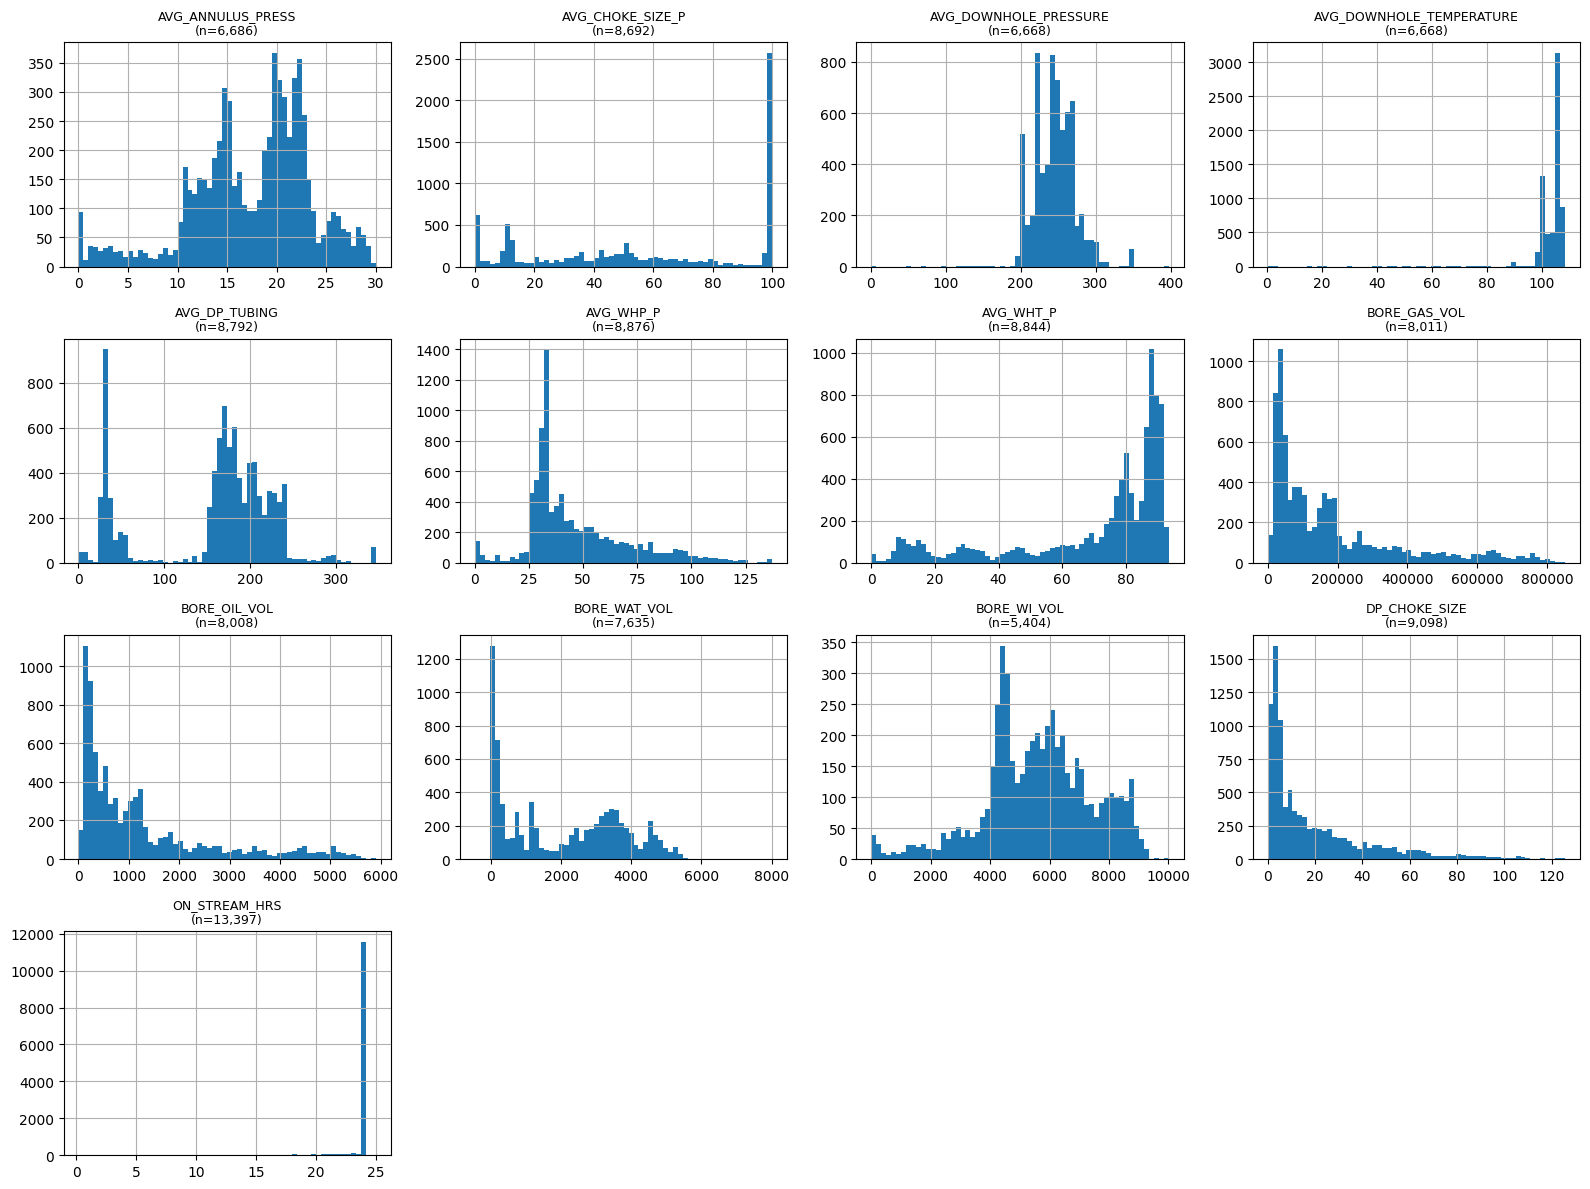

In [ ]:
ncols = 4
nrows = int(np.ceil(len(NUM_COLS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3 * nrows))
for ax, col in zip(axes.flat, NUM_COLS):
    values = daily[col].dropna()
    values = values[values != 0]
    ax.hist(values, bins=60)
    ax.set_title(f"{col}\n(n={len(values):,})", fontsize=9)
for ax in axes.flat[len(NUM_COLS):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### Корреляции параметров (добывающие скважины, ON_STREAM_HRS > 0)

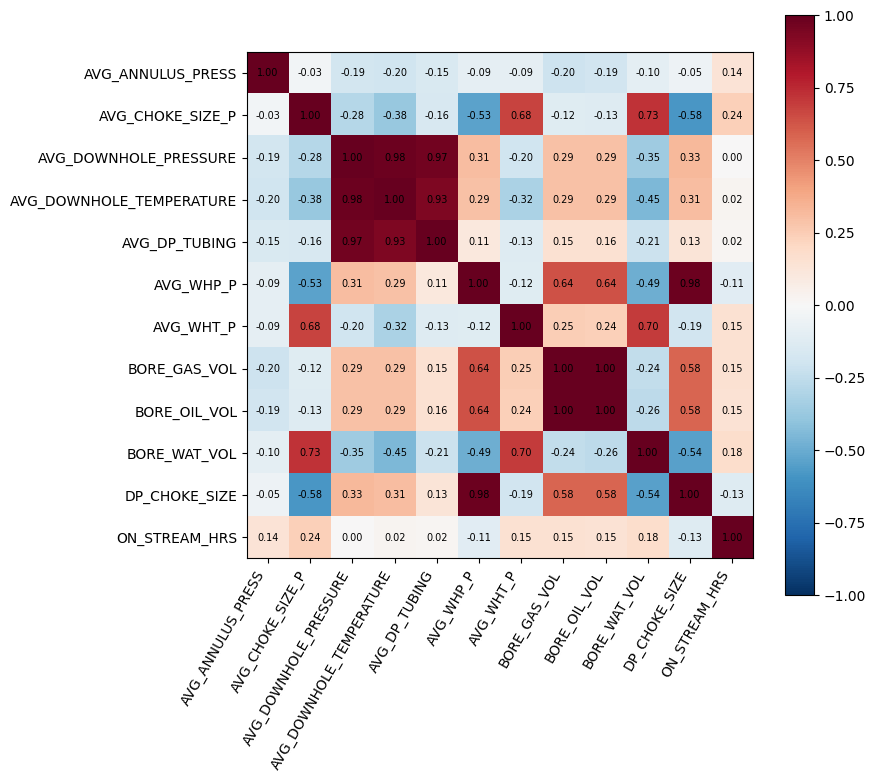

In [ ]:
prod = daily[(daily["FLOW_KIND"] == "production") & (daily["ON_STREAM_HRS"] > 0)]
corr_cols = [c for c in NUM_COLS if c != "BORE_WI_VOL"]
corr = prod[corr_cols].corr()

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=60, ha="right")
ax.set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False)
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## Месячные данные

Первая строка листа содержит единицы измерения, а не данные — выносим её отдельно и приводим колонки к числам.

In [ ]:
units_row = monthly_raw.iloc[0]
monthly_units = units_row.dropna().to_dict()
print("Единицы:", monthly_units)

monthly = monthly_raw.iloc[1:].copy()
monthly = monthly.dropna(how="all")
value_cols = ["On Stream", "Oil", "Gas", "Water", "GI", "WI"]
for col in ["NPDCode", "Year", "Month", *value_cols]:
    monthly[col] = pd.to_numeric(monthly[col], errors="coerce")

# Строки без скважины/даты (итоги, примечания) — смотрим отдельно
bad_rows = monthly[monthly[["Wellbore name", "Year", "Month"]].isna().any(axis=1)]
print(f"Строк без скважины или даты: {len(bad_rows)}")
display(bad_rows)

monthly = monthly.drop(bad_rows.index)
monthly[["NPDCode", "Year", "Month"]] = monthly[["NPDCode", "Year", "Month"]].astype(int)
monthly["date"] = pd.to_datetime(dict(year=monthly["Year"], month=monthly["Month"], day=1))
monthly = monthly.reset_index(drop=True)
monthly.head()

Единицы: {'On Stream': 'hrs', 'Oil': 'Sm3', 'Gas': 'Sm3', 'Water': 'Sm3', 'GI': 'Sm3', 'WI': 'Sm3'}
Строк без скважины или даты: 0


,Wellbore name,NPDCode,Year,Month,On Stream,Oil,Gas,Water,GI,WI


,Wellbore name,NPDCode,Year,Month,On Stream,Oil,Gas,Water,GI,WI,date
0,15/9-F-1 C,7405,2014,4,227.50,"11,142.47","1,597,936.65",0.00,NaN,NaN,2014-04-01
1,15/9-F-1 C,7405,2014,5,733.83,"24,901.95","3,496,229.65",783.48,NaN,NaN,2014-05-01
2,15/9-F-1 C,7405,2014,6,705.92,"19,617.76","2,886,661.69","2,068.48",NaN,NaN,2014-06-01
3,15/9-F-1 C,7405,2014,7,742.42,"15,085.68","2,249,365.75","6,243.98",NaN,NaN,2014-07-01
4,15/9-F-1 C,7405,2014,8,432.99,"6,970.43","1,048,190.80","4,529.75",NaN,NaN,2014-08-01


In [ ]:
pd.DataFrame({
    "непустых": monthly.notna().sum(),
    "пропусков, %": monthly.isna().mean() * 100,
})

,непустых,"пропусков, %"
Wellbore name,526,0.00
NPDCode,526,0.00
Year,526,0.00
Month,526,0.00
On Stream,515,2.09
Oil,311,40.87
Gas,311,40.87
Water,311,40.87
GI,0,100.00
WI,201,61.79


In [ ]:
monthly[value_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
On Stream,515.00,595.90,196.68,0.00,561.33,683.74,720.00,745.00
Oil,311.00,"32,273.57","37,361.94",0.00,"6,085.66","17,870.72","37,607.39","166,439.67"
Gas,311.00,"4,743,956.39","5,302,562.27",0.00,"923,652.24","2,722,573.45","5,780,979.75","24,106,361.74"
Water,311.00,"49,255.88","47,458.16",0.00,"3,534.34","36,195.93","94,056.46","155,365.68"
GI,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WI,201.00,"150,896.19","56,431.41",0.00,"126,376.88","150,430.99","188,426.12","270,199.40"


In [ ]:
monthly.groupby(["Wellbore name"]).agg(
    месяцев=("date", "size"),
    начало=("date", "min"),
    конец=("date", "max"),
    нефть=("Oil", "sum"),
    газ=("Gas", "sum"),
    вода=("Water", "sum"),
    закачка_газа=("GI", "sum"),
    закачка_воды=("WI", "sum"),
)

,месяцев,начало,конец,нефть,газ,вода,закачка_газа,закачка_воды
Wellbore name,,,,,,,,
15/9-F-1 C,25,2014-04-01,2016-04-01,"177,709.33","26,440,918.60","207,302.39",0.00,0.00
15/9-F-11,39,2013-07-01,2016-09-01,"1,147,849.10","174,310,520.61","1,090,806.27",0.00,0.00
15/9-F-12,104,2008-02-01,2016-09-01,"4,579,609.55","667,542,278.02","6,833,320.37",0.00,0.00
15/9-F-14,104,2008-02-01,2016-09-01,"3,942,233.39","578,009,542.02","7,121,249.74",0.00,0.00
15/9-F-15 D,33,2014-01-01,2016-09-01,"148,518.56","22,505,350.95","52,366.40",0.00,0.00
15/9-F-4,112,2007-09-01,2016-12-01,0.00,0.00,0.00,0.00,"16,240,727.04"
15/9-F-5,109,2007-09-01,2016-09-01,"41,160.68","6,561,825.74","13,533.18",0.00,"14,089,406.49"


### Добыча по месторождению в целом (сумма по скважинам)

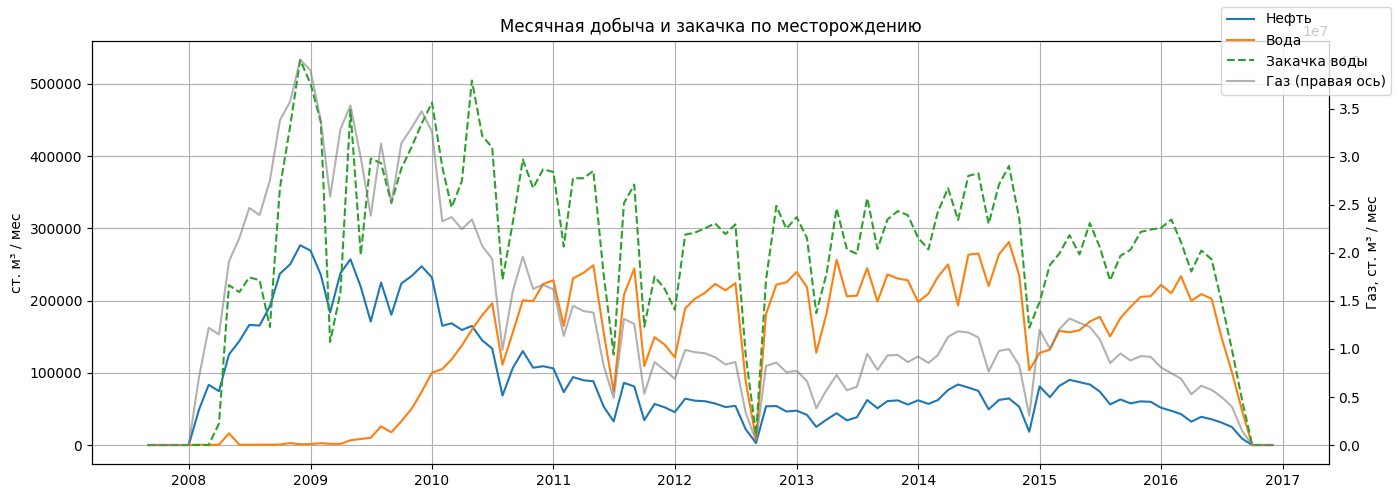

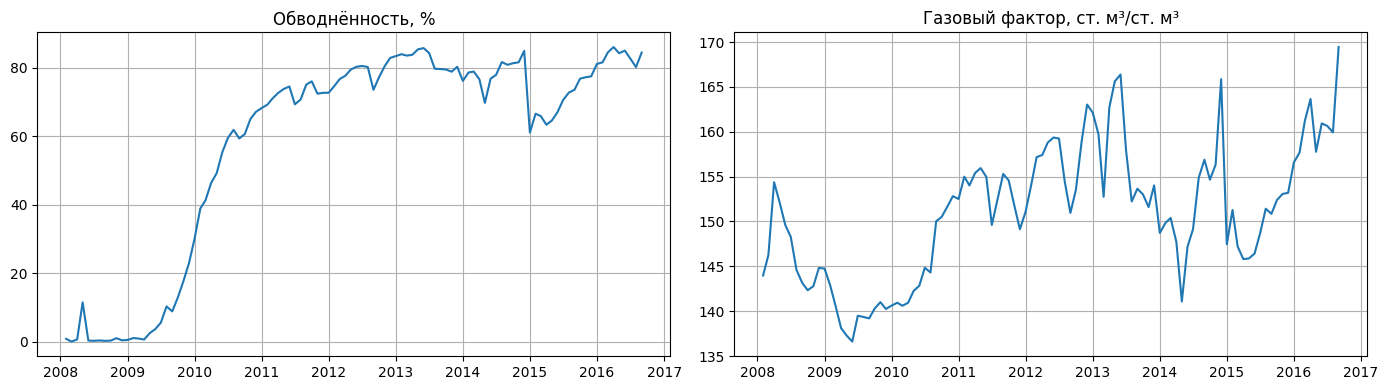

In [ ]:
field = monthly.groupby("date")[["Oil", "Gas", "Water", "WI"]].sum()

fig, ax = plt.subplots()
ax.plot(field.index, field["Oil"], label="Нефть")
ax.plot(field.index, field["Water"], label="Вода")
ax.plot(field.index, field["WI"], label="Закачка воды", ls="--")
ax.set_ylabel("ст. м³ / мес")
ax2 = ax.twinx()
ax2.plot(field.index, field["Gas"], color="tab:gray", alpha=0.6, label="Газ (правая ось)")
ax2.set_ylabel("Газ, ст. м³ / мес")
ax2.grid(False)
fig.legend(loc="upper right")
ax.set_title("Месячная добыча и закачка по месторождению")
plt.tight_layout()
plt.show()

water_cut = (field["Water"] / (field["Oil"] + field["Water"])).replace([np.inf, -np.inf], np.nan)
gor = (field["Gas"] / field["Oil"]).replace([np.inf, -np.inf], np.nan)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(water_cut.index, water_cut * 100)
axes[0].set_title("Обводнённость, %")
axes[1].plot(gor.index, gor)
axes[1].set_title("Газовый фактор, ст. м³/ст. м³")
plt.tight_layout()
plt.show()

## Согласованность суточных и месячных данных

Агрегируем суточные данные по месяцам и сравниваем с месячным листом.

In [ ]:
daily_agg = (
    daily.assign(date=daily["DATEPRD"].dt.to_period("M").dt.to_timestamp())
    .groupby(["NPD_WELL_BORE_CODE", "date"])
    .agg(
        on_stream_d=("ON_STREAM_HRS", "sum"),
        oil_d=("BORE_OIL_VOL", "sum"),
        gas_d=("BORE_GAS_VOL", "sum"),
        water_d=("BORE_WAT_VOL", "sum"),
        wi_d=("BORE_WI_VOL", "sum"),
    )
    .reset_index()
)

cmp = monthly.merge(
    daily_agg,
    left_on=["NPDCode", "date"],
    right_on=["NPD_WELL_BORE_CODE", "date"],
    how="outer",
    indicator=True,
)
print(cmp["_merge"].value_counts().rename({"left_only": "только месячные", "right_only": "только суточные"}))

pairs = [("On Stream", "on_stream_d"), ("Oil", "oil_d"), ("Gas", "gas_d"), ("Water", "water_d"), ("WI", "wi_d")]
both = cmp[cmp["_merge"] == "both"]
summary = {}
for m_col, d_col in pairs:
    m, d = both[m_col].fillna(0), both[d_col].fillna(0)
    rel = (m - d).abs() / m.abs().clip(lower=1)
    summary[m_col] = {
        "сумма (месячные)": m.sum(),
        "сумма (суточные)": d.sum(),
        "отклонение суммы, %": (d.sum() - m.sum()) / m.sum() * 100 if m.sum() else np.nan,
        "месяцев с расхождением > 5%": (rel > 0.05).sum(),
    }
pd.DataFrame(summary).T

_merge
both               526
только месячные      0
только суточные      0
Name: count, dtype: int64


,сумма (месячные),сумма (суточные),"отклонение суммы, %",месяцев с расхождением > 5%
On Stream,"306,889.34","306,889.34",0.00,0.00
Oil,"10,037,080.61","10,037,080.61",0.00,0.00
Gas,"1,475,370,435.94","1,475,370,435.94",0.00,0.00
Water,"15,318,578.35","15,318,578.35",0.00,0.00
WI,"30,330,133.53","30,330,133.53",-0.00,0.00


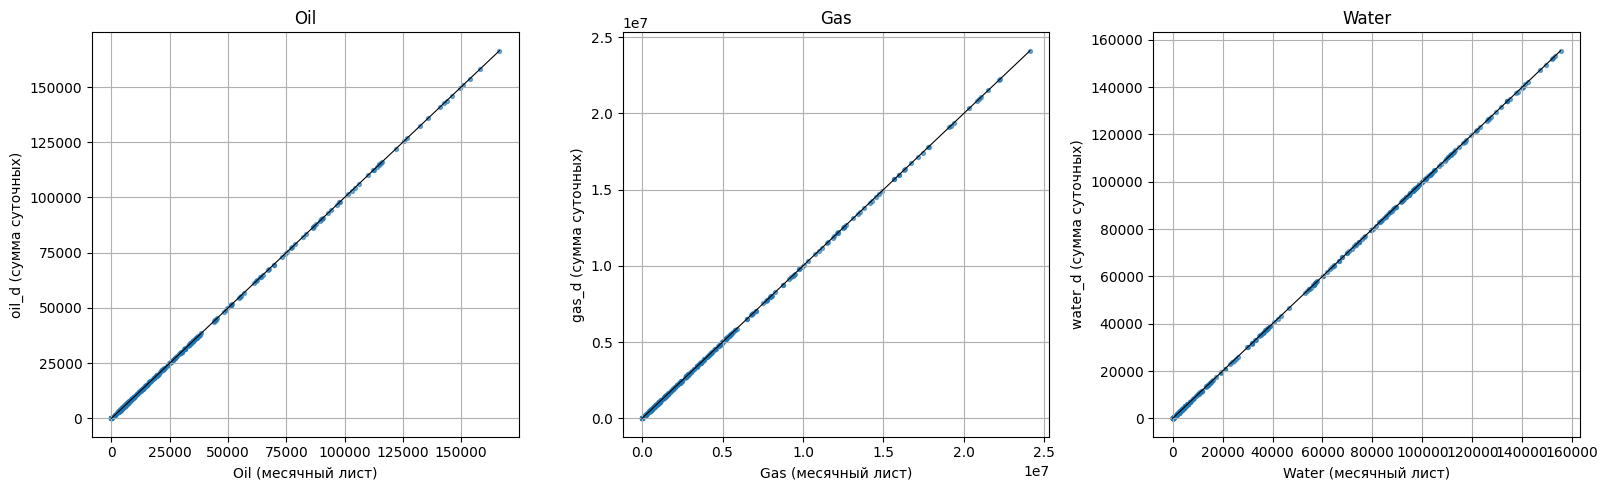

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (m_col, d_col) in zip(axes, pairs[1:4]):
    ax.scatter(both[m_col], both[d_col], s=8, alpha=0.6)
    lim = np.nanmax([both[m_col].max(), both[d_col].max()])
    ax.plot([0, lim], [0, lim], color="k", lw=0.8)
    ax.set_xlabel(f"{m_col} (месячный лист)")
    ax.set_ylabel(f"{d_col} (сумма суточных)")
    ax.set_title(m_col)
plt.tight_layout()
plt.show()

## Итоги обзора

Заполните после запуска: основные наблюдения о качестве данных, пропусках, расхождениях между листами
и о том, какие колонки/скважины/периоды стоит использовать дальше.

**Основные наблюдения о качестве данных и пропусках**
1. Качество и предобработка (Daily Production Data): Данные обладают высокой плотностью, однако требуют обязательной очистки.
2. Выявлено 2312 строк с ложным нулевым значением забойного давления (AVG_DOWNHOLE_PRESSURE = 0) и аналогичные провалы температуры до 0 °C в периоды работы скважин. Прямое помесячное усреднение исказит признаки.
3. Физические аномалии: Обнаружено 4 строки с физически невозможной отрицательной добычей воды (до -457.84) и 20 строк с превышением суточного лимита времени (ON_STREAM_HRS > 24). Отрицательные объемы необходимо приравнять к 0, а часы — клиппировать до 24.0.
4. Константы. Колонки:
  * NPD_FIELD_NAME = Volve,
  * NPD_FIELD_CODE,
  * NPD_FACILITY_NAME,
  * NPD_FACILITY_CODE.  
  Cодержат по 1 уникальному значению. Их необходимо удалить из признаков модели.
5. Природа пропусков (NaN): Высокий процент пропусков в объемах добычи нефти, газа и воды на обоих листах (~41%) строго обоснован физически — это периоды времени, когда конкретные скважины еще не были запущены или уже находились в глушении. Заполнение их средними или интерполяцией запрещено.
6. Это затухающее месторождение, о чём свидетельствую месячные данные.


**Расхождения между листами**
1. Математическая сходимость: Проверка слияния через merge(how='outer') показала идеальную сходимость строк (526 из 526 месяцев).
2. Сходимость объемов: Отклонение накопленных сумм по всем целевым показателям и времени работы между суточным и месячным листом составляет строго 0.00%. Месячный лист является чистым математическим результатом суммирования суточных рапортов, скрытых расхождений в учете нет.


**Какие колонки, скважины и периоды стоит использовать дальше**
1. Рекомендуемый период: Необходимо использовать весь доступный исторический период (с 2007 по сентябрь 2016 года). Временной ряд длиной почти 9 лет (более 100 расчетных месяцев) обеспечивает достаточный объем выборки для прогнозирования на целевой горизонт 6–12 месяцев.
2. Приоритетные скважины: В моделировании участвуют все 7 уникальных скважин, однако их роли разделяются:
  * 15/9-F-12 и 15/9-F-14 — главные добывающие флагманы месторождения (суммарно более 8.5 млн м³ нефти) с самой длинной и непрерывной историей (более 3100 дней). Прогноз по ним критичен для точности оперативного плана.
	* 15/9-F-4 — чисто нагнетательная скважина (16.2 млн м³ закачки), ее данные по объемам добычи использовать нельзя (они пустые), но объемы ее закачки важны как предикторы ППД.
	* 15/9-F-5 — смешанная скважина. Требует разделения истории на два этапа из-за перевода с добычи на закачку.


**Итог:** Сама модель будет месячной (прогноз на 1, 2, 3... 12 месяцев вперед), но сетка её признаков (матрица обучения) будет построена на основе суточной аналитики.  
**Таргет:**
- Oil,
- Gas,
- Water.

**Датафреймы**
* daily - основной массив суточных данных (15 634 строки)
* monthly - агрегированные коммерческие показатели по месяцам (527 строк).
* col_info - Плоская таблица, полученная из исходного листа "Описание колонок". Служит для расшифровки параметров.

## Очистка суточных данных

In [ ]:
daily = daily_raw.copy()
daily["DATEPRD"] = pd.to_datetime(daily["DATEPRD"])
daily = daily.sort_values(["NPD_WELL_BORE_NAME", "DATEPRD"]).reset_index(drop=True)

overview = pd.DataFrame({
    "dtype": daily.dtypes.astype(str),
    "непустых": daily.notna().sum(),
    "пропусков, %": daily.isna().mean() * 100,
    "уникальных": daily.nunique(),
})
if not col_info.empty:
    overview = overview.join(col_info[["Русское название", "Единица"]])
overview

,dtype,непустых,"пропусков, %",уникальных,Русское название,Единица
DATEPRD,datetime64[ns],15634,0.00,3327,Дата добычи,—
WELL_BORE_CODE,object,15634,0.00,7,Код ствола скважины,—
NPD_WELL_BORE_CODE,int64,15634,0.00,7,Код ствола в NPD,—
NPD_WELL_BORE_NAME,object,15634,0.00,7,Название ствола в NPD,—
NPD_FIELD_CODE,int64,15634,0.00,1,Код месторождения в NPD,—
NPD_FIELD_NAME,object,15634,0.00,1,Название месторождения,—
NPD_FACILITY_CODE,int64,15634,0.00,1,Код производственного объекта,—
NPD_FACILITY_NAME,object,15634,0.00,1,Название производственного объекта,—
ON_STREAM_HRS,float64,15349,1.82,925,Время работы за сутки,ч
AVG_DOWNHOLE_PRESSURE,float64,8980,42.56,6567,Среднее забойное давление,бар


#### Удаляем константные значения

In [ ]:
## удалим константные значения:
# NPD_FIELD_NAME,
# NPD_FIELD_CODE,
# NPD_FACILITY_NAME,
# NPD_FACILITY_CODE.

const_columns = ['NPD_FIELD_NAME', 'NPD_FIELD_CODE', 'NPD_FACILITY_NAME', 'NPD_FACILITY_CODE']
daily_clean = daily.drop(columns = const_columns)

#### Обрабатываем пропуски и выбросы

In [ ]:
daily_clean.describe().T

,count,mean,min,25%,50%,75%,max,std
DATEPRD,15634,2012-11-07 17:39:58.004349440,2007-09-01 00:00:00,2010-07-30 00:00:00,2013-05-08 00:00:00,2015-02-19 00:00:00,2016-12-01 00:00:00,NaN
NPD_WELL_BORE_CODE,"15,634.00","5,908.58","5,351.00","5,599.00","5,693.00","5,769.00","7,405.00",649.23
ON_STREAM_HRS,"15,349.00",19.99,0.00,24.00,24.00,24.00,25.00,8.37
AVG_DOWNHOLE_PRESSURE,"8,980.00",181.80,0.00,0.00,232.90,255.40,397.59,109.71
AVG_DOWNHOLE_TEMPERATURE,"8,980.00",77.16,0.00,0.00,103.19,106.28,108.50,45.66
AVG_DP_TUBING,"8,980.00",154.03,0.00,83.67,175.59,204.32,345.91,76.75
AVG_ANNULUS_PRESS,"7,890.00",14.86,0.00,10.84,16.31,21.31,30.02,8.41
AVG_CHOKE_SIZE_P,"8,919.00",55.17,0.00,18.95,52.10,99.92,100.00,36.69
AVG_WHP_P,"9,155.00",45.38,0.00,31.15,37.93,57.10,137.31,24.75
AVG_WHT_P,"9,146.00",67.73,0.00,56.58,80.07,88.06,93.51,27.72


In [ ]:
# проверки качества
checks = {
    "дубликаты (скважина, дата)": daily_clean.duplicated(["NPD_WELL_BORE_NAME", "DATEPRD"]).sum(),
    "ON_STREAM_HRS > 24": (daily_clean["ON_STREAM_HRS"] > 24).sum(),
    "ON_STREAM_HRS < 0": (daily_clean["ON_STREAM_HRS"] < 0).sum(),
    "отрицательные объёмы": (daily_clean[["BORE_OIL_VOL", "BORE_GAS_VOL", "BORE_WAT_VOL", "BORE_WI_VOL"]] < 0).sum().sum(),
    "добыча при ON_STREAM_HRS = 0": ((daily_clean["ON_STREAM_HRS"] == 0) & (daily["BORE_OIL_VOL"] > 0)).sum(),
    "давление на забое = 0": (daily_clean["AVG_DOWNHOLE_PRESSURE"] == 0).sum(),
    "отрицательные давления/перепады": (
        daily_clean[["AVG_DOWNHOLE_PRESSURE", "AVG_DP_TUBING", "AVG_ANNULUS_PRESS", "AVG_WHP_P", "DP_CHOKE_SIZE"]] < 0
    ).sum().sum(),
}
pd.Series(checks, name="строк").to_frame()

,строк
"дубликаты (скважина, дата)",0
ON_STREAM_HRS > 24,20
ON_STREAM_HRS < 0,0
отрицательные объёмы,4
добыча при ON_STREAM_HRS = 0,1
давление на забое = 0,2312
отрицательные давления/перепады,0


ON_STREAM_HRS (время работы в часах):
  - пропуски заменяем на 0,
  - значения < 0 на 0,
  - значения > 24 на 24.

In [ ]:
# обработка даты
daily_clean['ON_STREAM_HRS'] = daily_clean['ON_STREAM_HRS'].fillna(0).clip(lower=0, upper=24)

в BORE_WAT_VOL (Суточная добыча воды) есть отрицательные значения:
  - отрицательные значения заменяем на 0.

In [ ]:
daily_clean.loc[daily_clean['BORE_WAT_VOL'] < 0, 'BORE_WAT_VOL'] = 0.0

добыча при ON_STREAM_HRS (время работы в часах) = 0
  - удалим эту строку, тк количество таких строк = 1.

In [ ]:
daily_clean = daily_clean[~((daily_clean["ON_STREAM_HRS"] == 0) & (daily_clean["BORE_OIL_VOL"] > 0))]

In [ ]:
# проверки качества
checks = {
    "дубликаты (скважина, дата)": daily_clean.duplicated(["NPD_WELL_BORE_NAME", "DATEPRD"]).sum(),
    "ON_STREAM_HRS > 24": (daily_clean["ON_STREAM_HRS"] > 24).sum(),
    "ON_STREAM_HRS < 0": (daily_clean["ON_STREAM_HRS"] < 0).sum(),
    "отрицательные объёмы": (daily_clean[["BORE_OIL_VOL", "BORE_GAS_VOL", "BORE_WAT_VOL", "BORE_WI_VOL"]] < 0).sum().sum(),
    "добыча при ON_STREAM_HRS = 0": ((daily_clean["ON_STREAM_HRS"] == 0) & (daily["BORE_OIL_VOL"] > 0)).sum(),
    "давление на забое = 0": (daily_clean["AVG_DOWNHOLE_PRESSURE"] == 0).sum(),
    "отрицательные давления/перепады": (
        daily_clean[["AVG_DOWNHOLE_PRESSURE", "AVG_DP_TUBING", "AVG_ANNULUS_PRESS", "AVG_WHP_P", "DP_CHOKE_SIZE"]] < 0
    ).sum().sum(),
}
pd.Series(checks, name="строк").to_frame()

,строк
"дубликаты (скважина, дата)",0
ON_STREAM_HRS > 24,0
ON_STREAM_HRS < 0,0
отрицательные объёмы,0
добыча при ON_STREAM_HRS = 0,0
давление на забое = 0,2312
отрицательные давления/перепады,0


In [ ]:
wells = daily_clean.groupby("NPD_WELL_BORE_NAME").agg(
    записей=("DATEPRD", "size"),
    начало=("DATEPRD", "min"),
    конец=("DATEPRD", "max"),
    тип=("WELL_TYPE", lambda s: ", ".join(sorted(s.unique()))),
    операция=("FLOW_KIND", lambda s: ", ".join(sorted(s.unique()))),
    нефть_ст_м3=("BORE_OIL_VOL", "sum"),
    газ_ст_м3=("BORE_GAS_VOL", "sum"),
    вода_ст_м3=("BORE_WAT_VOL", "sum"),
    закачка_воды_ст_м3=("BORE_WI_VOL", "sum"),
)
wells["дней_в_периоде"] = (wells["конец"] - wells["начало"]).dt.days + 1
wells["пропущено_дат"] = wells["дней_в_периоде"] - wells["записей"]

# Постоянный цвет для каждой скважины на всех графиках
WELL_COLORS = dict(zip(wells.index, plt.cm.tab10.colors))
wells

,записей,начало,конец,тип,операция,нефть_ст_м3,газ_ст_м3,вода_ст_м3,закачка_воды_ст_м3,дней_в_периоде,пропущено_дат
NPD_WELL_BORE_NAME,,,,,,,,,,,
15/9-F-1 C,746,2014-04-07,2016-04-21,"OP, WI",production,"177,709.33","26,440,918.60","207,302.39",0.00,746,0
15/9-F-11,1164,2013-07-08,2016-09-17,OP,production,"1,146,822.53","174,159,747.11","1,090,345.25",0.00,1168,4
15/9-F-12,3056,2008-02-12,2016-09-17,OP,production,"4,579,609.55","667,542,278.02","6,833,792.40",0.00,3141,85
15/9-F-14,3056,2008-02-12,2016-09-17,OP,production,"3,942,233.39","578,009,542.02","7,121,309.88",0.00,3141,85
15/9-F-15 D,978,2014-01-12,2016-09-17,OP,production,"148,518.56","22,505,350.95","52,366.40",0.00,980,2
15/9-F-4,3327,2007-09-01,2016-12-01,WI,injection,0.00,0.00,0.00,"16,240,727.04",3380,53
15/9-F-5,3306,2007-09-01,2016-09-18,"OP, WI","injection, production","41,160.68","6,561,825.74","13,533.18","14,089,406.49",3306,0


### Удаляем лишние данные

Скважины, у которых эксплуатационный период мал, можно убрать из данных:  
  - 15/9-F-1 C [WI, OP]
  - 15/9-F-15 D [OP]

In [ ]:
# Скважины, у которых эксплуатационный период мал, можно убрать из данных:
#   - 15/9-F-1 C [WI, OP]
#   - 15/9-F-15 D [OP]

wells_to_drop = ['15/9-F-1 C', '15/9-F-15 D']
daily_clean = daily_clean[~daily_clean['NPD_WELL_BORE_NAME'].isin(wells_to_drop)].reset_index(drop=True)

In [ ]:
# фильтруем данные по скважине 15/9-F-5 и только для дней фактической работы
w5_active = daily_clean[(daily_clean['NPD_WELL_BORE_NAME'] == '15/9-F-5') & (daily_clean['ON_STREAM_HRS'] > 0)]

w5_counts = w5_active['WELL_TYPE'].value_counts()
w5_pct = w5_active['WELL_TYPE'].value_counts(normalize=True) * 100

# Режим добычи
op_days = w5_counts.get('OP', 0)
op_pct = w5_pct.get('OP', 0.0)
print(f"Добывающая скважина (OP / Production):   {op_days:>4} дней ({op_pct:.2f}%)")

# Режим нагнетания
wi_days = w5_counts.get('WI', 0)
wi_pct = w5_pct.get('WI', 0.0)
print(f"Нагнетательная скважина (WI / Injection): {wi_days:>4} дней ({wi_pct:.2f}%)")

print(f"Всего активных дней эксплуатации:       {w5_active.shape[0]} дней")

Добывающая скважина (OP / Production):    121 дней (4.52%)
Нагнетательная скважина (WI / Injection): 2555 дней (95.48%)
Всего активных дней эксплуатации:       2676 дней


Уберём из данных строки, когда скважина 15/9-F-5 работала как добывающая - это слишком маленький срок, эти строки создадут шум в данных.

In [ ]:
# находим индексы строк, где скважина 15/9-F-5 работала в режиме добычи (OP)
indices_to_drop = daily_clean[
    (daily_clean['NPD_WELL_BORE_NAME'] == '15/9-F-5') &
    (daily_clean['WELL_TYPE'] == 'OP')
].index

daily_clean = daily_clean.drop(index=indices_to_drop).reset_index(drop=True)

### Заполняем пропуски по скважинам

Заполняем пропуски в технологических данных (датчиках):
  - "AVG_DOWNHOLE_PRESSURE",
  - "AVG_DOWNHOLE_TEMPERATURE",
  - "AVG_DP_TUBING",
  - "AVG_ANNULUS_PRESS",
  - "AVG_CHOKE_SIZE_P",
  - "AVG_WHP_P",
  - "AVG_WHT_P",
  - "DP_CHOKE_SIZE".   
Используем метод "K ближайших соседей" (KNN). K = 5  
Применим его к каждой скважине по отдельности и только к тем колонкам, в которых есть данные:
  - 15/9-F-11          [OP]
  - 15/9-F-12          [OP]
  - 15/9-F-14          [OP]
  - 15/9-F-4           [WI]
  - 15/9-F-5           [WI]


Обработка добывающего фонда ("15/9-F-11", "15/9-F-12", "15/9-F-14")

In [ ]:
from sklearn.impute import KNNImputer

#Обработка добывающего фонда ("15/9-F-11", "15/9-F-12", "15/9-F-14")
SENSOR_COLS = [
    "AVG_DOWNHOLE_PRESSURE",    # Забойное давление
    "AVG_DP_TUBING",            # Перепад давления в НКТ
    "AVG_ANNULUS_PRESS",        # Затрубное давление
    "AVG_CHOKE_SIZE_P",         # Размер штуцера в %
    "AVG_WHP_P",                # Устьевое давление
    "AVG_WHT_P",                # Устьевая температура
    "AVG_DOWNHOLE_TEMPERATURE", # Средняя температура на глубине установки датчика.
    "DP_CHOKE_SIZE",            # Разница давлений до и после штуцера
]

ONSTREAM_COL = 'ON_STREAM_HRS'
OIL_COL = 'BORE_OIL_VOL'
GAS_COL = 'BORE_GAS_VOL'
WATER_COL = 'BORE_WAT_VOL'
WELL_NAME_COL = 'NPD_WELL_BORE_NAME'

daily_result = daily_clean.copy()

target_prod_wells = ["15/9-F-11", "15/9-F-12", "15/9-F-14"]
daily_n = daily_result[daily_result[WELL_NAME_COL].isin(target_prod_wells)].copy()

# отмечаем дни простоя и зануляем пропуски добычи в эти дни
daily_n["is_downtime"] = (daily_n[ONSTREAM_COL] < 1.0).astype("int8")
for col in [OIL_COL, GAS_COL, WATER_COL]:
    daily_n.loc[(daily_n["is_downtime"] == 1) & daily_n[col].isna(), col] = 0.0

# функция изолированного импутинга внутри добывающих скважин
def impute_well(g):
    g = g.copy()
    valid_cols = [col for col in SENSOR_COLS if not g[col].isna().all()]
    if valid_cols:
        g[valid_cols] = KNNImputer(n_neighbors=5).fit_transform(g[valid_cols])

    for col in [OIL_COL, GAS_COL, WATER_COL]:
        g[col] = g[col].interpolate(method="spline", order=2, limit_direction="both")
    return g

daily_n = daily_n.groupby(WELL_NAME_COL, group_keys=False).apply(impute_well)

daily_result.update(daily_n)

/tmp/ipykernel_5665/4265394173.py:42: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  daily_n = daily_n.groupby(WELL_NAME_COL, group_keys=False).apply(impute_well)


Обработка нагнетательных скважин ("15/9-F-4", "15/9-F-5")

In [ ]:
# обработка нагнетательных скважин ("15/9-F-4", "15/9-F-5")

WI_COL = 'BORE_WI_VOL'
CHOKE_COL = 'DP_CHOKE_SIZE'

target_inj_wells = ["15/9-F-4", "15/9-F-5"]
daily_clean_inj = daily_result[daily_result[WELL_NAME_COL].isin(target_inj_wells)].copy()

# зануление параметров в простои
is_inj_downtime = daily_clean_inj[ONSTREAM_COL] < 1.0
daily_clean_inj.loc[is_inj_downtime, WI_COL] = 0.0
daily_clean_inj.loc[is_inj_downtime, CHOKE_COL] = 0.0

# протяжка штуцера (ffill/bfill) внутри групп скважин
daily_clean_inj[CHOKE_COL] = daily_clean_inj.groupby(WELL_NAME_COL)[CHOKE_COL].ffill()
daily_clean_inj[CHOKE_COL] = daily_clean_inj.groupby(WELL_NAME_COL)[CHOKE_COL].bfill()

# линейная интерполяция объёмов закачки
daily_clean_inj[WI_COL] = daily_clean_inj.groupby(WELL_NAME_COL)[WI_COL].transform(
    lambda x: x.interpolate(method='linear', limit_direction='both')
)

daily_result.update(daily_clean_inj)

In [ ]:
# проверим значения скважины 15/9-F-5
series = daily_clean[(daily_clean['NPD_WELL_BORE_NAME'] == '15/9-F-5') & (daily_clean["ON_STREAM_HRS"] > 0)]['AVG_ANNULUS_PRESS']

# кол-во NaN
nan_count = series.isna().sum()
# кол-во 0
zero_count = (series == 0).sum()
# кол-во остальных значений
other_count = series.notna().sum() - zero_count

print(f"Пропущенных (NaN): {nan_count}")
print(f"Нулевых значений:  {zero_count}")
print(f"Других значений:   {other_count}")
print(f"Всего строк:       {len(series)}")

Пропущенных (NaN): 2547
Нулевых значений:  0
Других значений:   8
Всего строк:       2555


Так как из скважины 15/9-F-5 мы убрали строки, когда она была добывающей (PO), то сейчас в ней остались строки, когда она была нагнетающей (WI).
Получается, что эти 8 значений и 0 можно заменить на NaN, согласно примеру скважины 15/9-F-4, которая всегда была нагнетающей (WI).

In [ ]:
# записываем значения NaN в выбранные столбцы для скважины скважины 15/9-F-5
target_cols = [
    "AVG_ANNULUS_PRESS", "AVG_CHOKE_SIZE_P", "AVG_DOWNHOLE_PRESSURE",
    "AVG_DOWNHOLE_TEMPERATURE", "AVG_DP_TUBING", "AVG_WHP_P",
    "AVG_WHT_P", "BORE_GAS_VOL", "BORE_OIL_VOL", "BORE_WAT_VOL"
]

daily_result.loc[daily_result['NPD_WELL_BORE_NAME'] == '15/9-F-5', target_cols] = np.nan

### Карта пропусков по скважинам (доля пропусков в колонке, %)

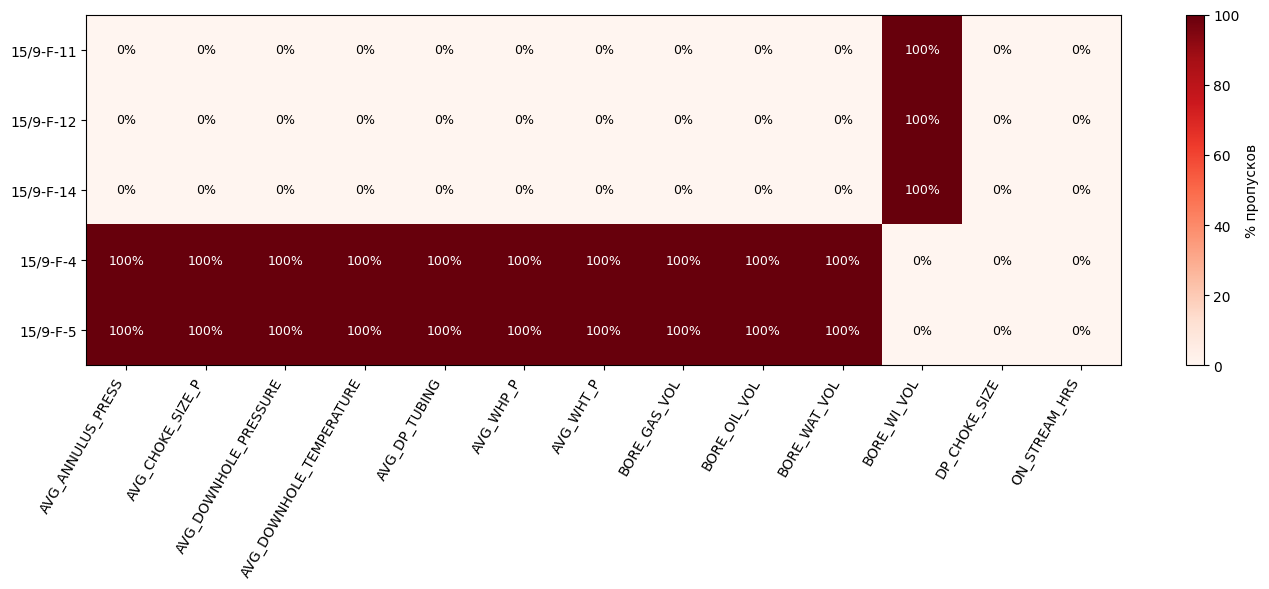

In [ ]:
na_by_well = daily_result.groupby("NPD_WELL_BORE_NAME")[NUM_COLS].agg(lambda s: s.isna().mean() * 100)

fig, ax = plt.subplots(figsize=(14, 6)) # Немного увеличили высоту для читаемости текста
im = ax.imshow(na_by_well.values, aspect="auto", cmap="Reds", vmin=0, vmax=100)

ax.set_xticks(range(len(NUM_COLS)))
ax.set_xticklabels(NUM_COLS, rotation=60, ha="right")
ax.set_yticks(range(len(na_by_well)))
ax.set_yticklabels(na_by_well.index)
ax.grid(False)

data_values = na_by_well.values
for i in range(data_values.shape[0]):
    for j in range(data_values.shape[1]):
        val = data_values[i, j]
        text_color = "white" if val > 60 else "black"
        text_label = f"{val:.0f}%" if val == 0 or val == 100 else f"{val:.1f}%"

        ax.text(j, i, text_label,
                ha="center", va="center",
                color=text_color, fontsize=9)

fig.colorbar(im, ax=ax, label="% пропусков")
plt.tight_layout()
plt.show()


### Распределения числовых параметров (только ненулевые значения)

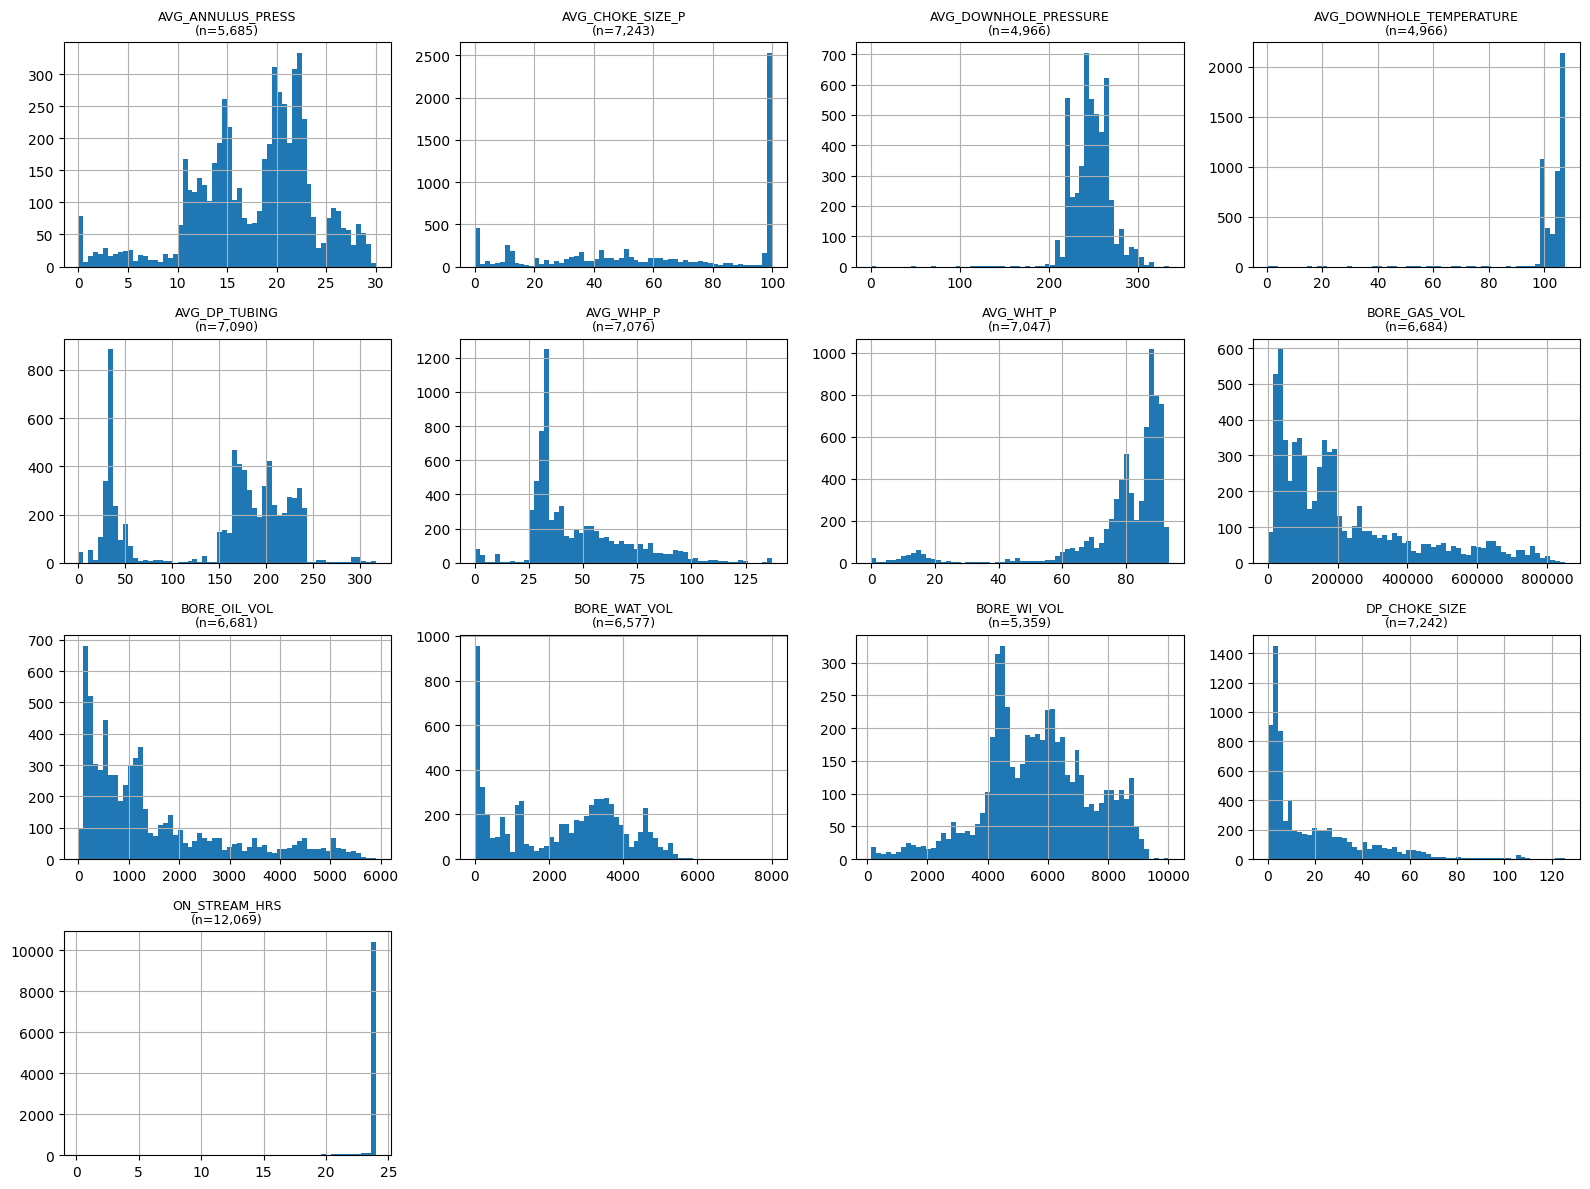

In [ ]:
ncols = 4
nrows = int(np.ceil(len(NUM_COLS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3 * nrows))
for ax, col in zip(axes.flat, NUM_COLS):
    values = daily_result[col].dropna()
    values = values[values != 0]
    ax.hist(values, bins=60)
    ax.set_title(f"{col}\n(n={len(values):,})", fontsize=9)
for ax in axes.flat[len(NUM_COLS):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### Корреляции параметров (добывающие скважины, ON_STREAM_HRS > 0)

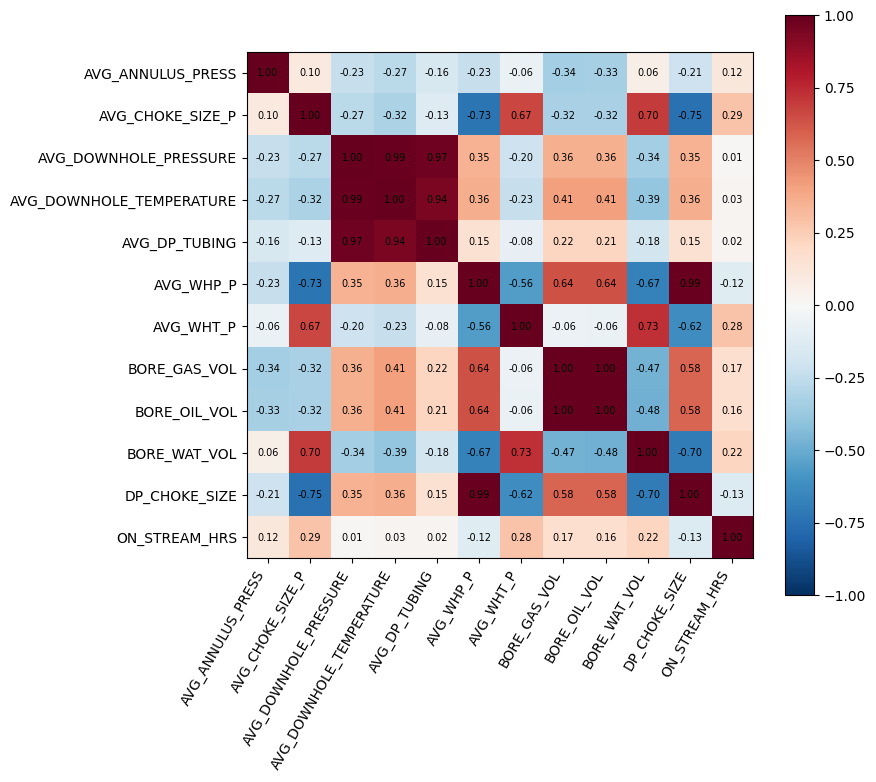

In [ ]:
prod = daily_result[(daily_result["FLOW_KIND"] == "production") & (daily_result["ON_STREAM_HRS"] > 0)]
corr_cols = [c for c in NUM_COLS if c != "BORE_WI_VOL"]
corr = prod[corr_cols].corr()

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=60, ha="right")
ax.set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False)
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

### Корреляция между фичами
**Очень сильная корреляция (>0,9):**
**Наблюдается мультиколлинеарность**
1. BORE_OIL_VOL (добыча нефти) и BORE_GAS_VOL (добыча газа)
2. Энергетика пласта. Рост забойного давления сопровождается увеличением температуры из-за притока горячего флюида из глубины пласта.   
  • AVG_DOWNHOLE_PRESSURE (забойное давление)  
  • AVG_DOWNHOLE_TEMPERATURE (забойная температура)   
  • AVG_DP_TUBING (перепад давления в НКТ)  
3. Устьевая арматура и штуцер.  
  • AVG_WHP_P (устьевое давление) и DP_CHOKE_SIZE (штуцер): корреляция +0.99.Почти абсолютная связь: положение задвижки штуцера напрямую формирует давление на устье скважины.  

**Сильная корреляция (>0,6):**
  - AVG_CHOKE_SIZE_P (размер штуцера в %) и устьевые параметры: корреляция от -0.73 до -0.75. Здесь корреляция отрицательная. Чем сильнее инженеры открывают штуцер (AVG_CHOKE_SIZE_P идет вверх), тем меньше становится гидравлическое сопротивление («зажим»), из-за чего давление перед задвижкой падает, а перепад давления на самом штуцере стремится к другим значениям.  
  - Взаимосвязь добычи воды и приборов (Связь -0.67 ... -0.70) — Обводнение
  - BORE_WAT_VOL (добыча воды) сильно обратно коррелирует с параметрами штуцера (-0.70) и устьевым давлением (-0.67). Когда скважина начинает выдавать огромные объемы пластовой воды вместо нефти, физика потока меняется. Вода тяжелее нефти, она «давит» на устьевые датчики иначе и заставляет инженеров менять положение регулирующих кранов штуцера, чтобы удерживать стабильную работу.


### Удаление признаков

**Что следует удалить:**  
*1. Удаляем BORE_GAS_VOL (Объем добычи газа), оставляем BORE_OIL_VOL (Объем добычи нефти).
Их корреляция равна идеальной единице. Попутный газ на Volve выходит вместе с нефтью в строгой пропорции (газовый фактор стабилен). Модели нет смысла предсказывать два одинаковых графика. Прогноз газа можно будет рассчитать, просто умножив спрогнозированную нефть на исторический газовый фактор.* - надо подумать

2. Удаляем AVG_DOWNHOLE_TEMPERATURE (Забойная температура), оставляем AVG_DOWNHOLE_PRESSURE (Забойное давление).
Для физики пласта и фильтрации флюида ключевым фактором является именно давление (энергетика пласта). Температура на глубине меняется строго вслед за давлением притока. Забойная температура не несет никакой новой информации для модели, но создает сильный математический шум из-за мультиколлинеарности.

3. Удаляем DP_CHOKE_SIZE (Перепад давления на штуцере), оставляем AVG_WHP_P (Устьевое давление).  
Эти параметры измеряются на поверхности в одной и той же точке устьевой арматуры и связаны прямой формулой гидравлики. Устьевое давление (WHP) является более стандартным, надежным и чистым физическим параметром для гидродинамического анализа, чем расчетный перепад на штуцере.

Не удаляем:
- Если забойное давление (DOWNHOLE) высокое, а перепад (DP_TUBING) маленький - значит, нефть летит наверх легко, обводненность низкая, скважина работает эффективно. Удаление одного из них лишило бы возможности оценивать качество подъема жидкости на поверхность.

In [ ]:
# список мультикоррелирующих признаков-дубликатов
cols_to_remove = ['AVG_DOWNHOLE_TEMPERATURE', 'DP_CHOKE_SIZE']

daily_res = daily_result.drop(columns=cols_to_remove, errors='ignore')

### Корреляции параметров (добывающие скважины, ON_STREAM_HRS > 0)

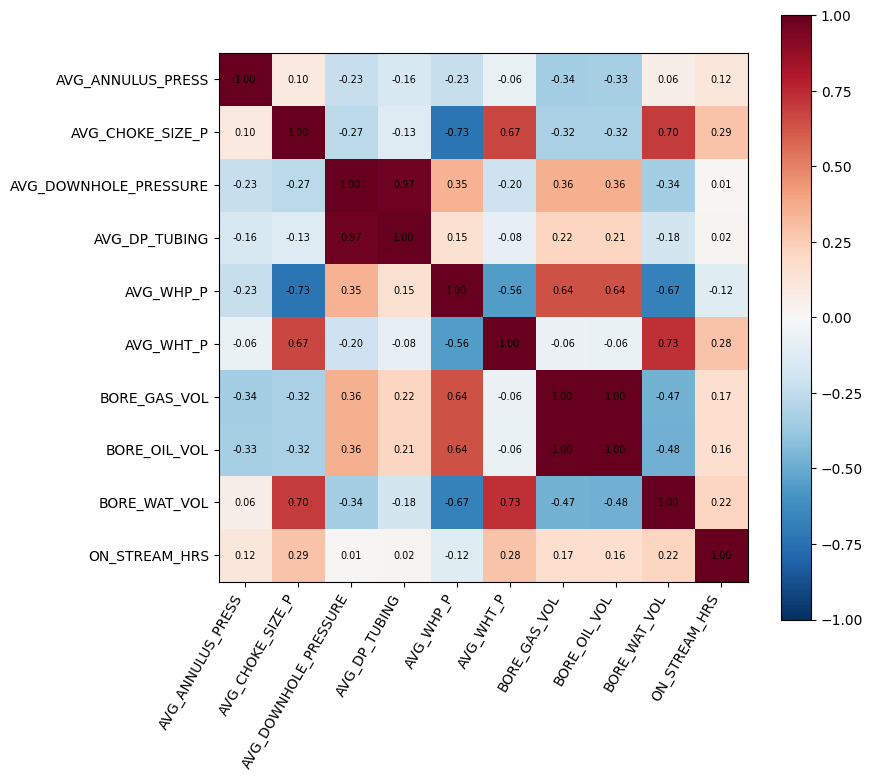

In [ ]:
prod = daily_res[(daily_res["FLOW_KIND"] == "production") & (daily_res["ON_STREAM_HRS"] > 0)]
corr_cols = [c for c in NUM_COLS if c in daily_res.columns and c != "BORE_WI_VOL"]

corr = prod[corr_cols].corr()

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=60, ha="right")
ax.set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False)
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

### Агрегация суточных данных

In [ ]:
# агрегируем суточные данные в календарные месяцы
daily_agg = (
    daily_res.assign(date=daily_res["DATEPRD"].dt.to_period("M").dt.to_timestamp())
    .groupby(["NPD_WELL_BORE_CODE", "date"])
    .agg(
        on_stream_d=("ON_STREAM_HRS", "sum"),
        oil_d=("BORE_OIL_VOL", "sum"),
        gas_d=("BORE_GAS_VOL", "sum"),
        water_d=("BORE_WAT_VOL", "sum"),
        wi_d=("BORE_WI_VOL", "sum"),
    )
    .reset_index()
)


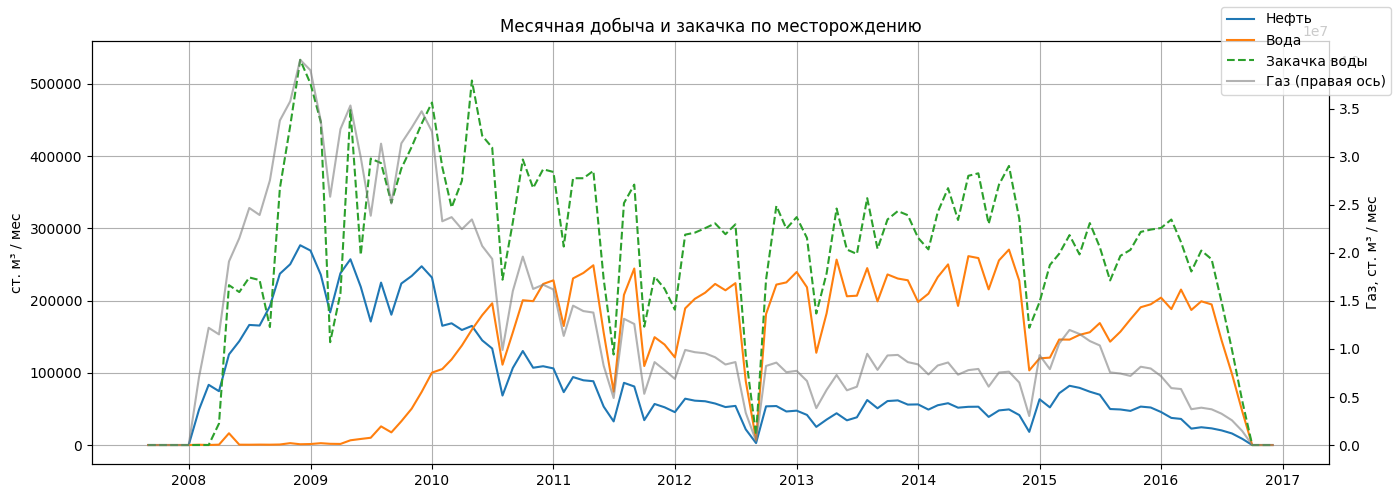

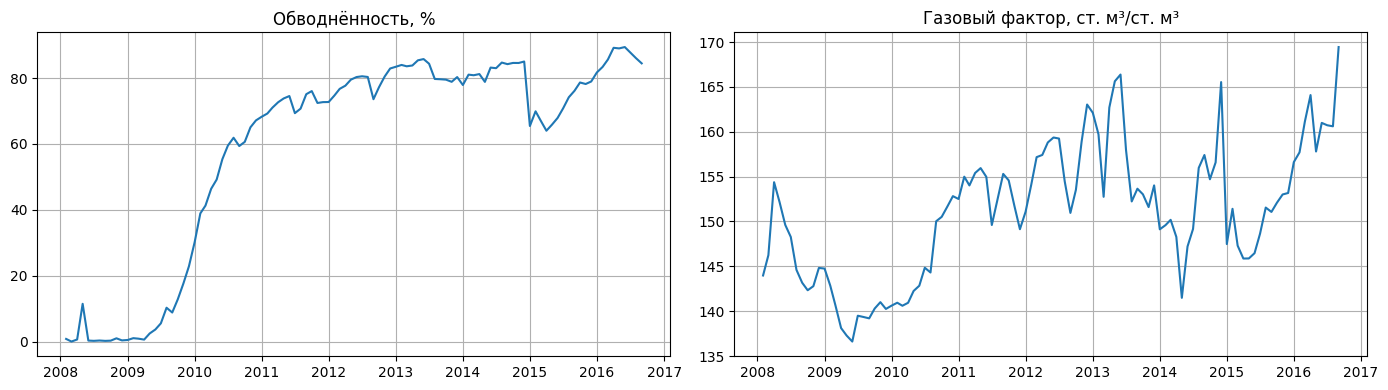

In [ ]:
field = daily_agg.groupby("date")[["oil_d", "gas_d", "water_d", "wi_d"]].sum()

fig, ax = plt.subplots()

ax.plot(field.index, field["oil_d"], label="Нефть")
ax.plot(field.index, field["water_d"], label="Вода")
ax.plot(field.index, field["wi_d"], label="Закачка воды", ls="--")
ax.set_ylabel("ст. м³ / мес")

ax2 = ax.twinx()
ax2.plot(field.index, field["gas_d"], color="tab:gray", alpha=0.6, label="Газ (правая ось)")
ax2.set_ylabel("Газ, ст. м³ / мес")
ax2.grid(False)

fig.legend(loc="upper right")
ax.set_title("Месячная добыча и закачка по месторождению")
plt.tight_layout()
plt.show()

water_cut = (field["water_d"] / (field["oil_d"] + field["water_d"])).replace([np.inf, -np.inf], np.nan)
gor = (field["gas_d"] / field["oil_d"]).replace([np.inf, -np.inf], np.nan)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(water_cut.index, water_cut * 100)
axes[0].set_title("Обводнённость, %")
axes[1].plot(gor.index, gor)
axes[1].set_title("Газовый фактор, ст. м³/ст. м³")
plt.tight_layout()
plt.show()

### Сезонность и поведение графиков
Сезонность не обнаружена.

Глубокий провал в графиках в конце 2012 - начале 2013 года (когда добыча нефти, воды и объёмы закачки практически одновременно рухнули до нуля) обусловлен масштабной технической модернизацией и плановым капитальным ремонтом платформы.
В истории разработки шельфового месторождения Volve этот период примечателен следующими событиями:
1. Модернизация буровой установки: В 2012 году гигантская самоподъёмная буровая установка Maersk Inspirer (которая обслуживала всё месторождение) была временно остановлена для проведения планового технического освидетельствования и крупного инженерного апгрейда. Для выполнения этих опасных работ на платформе полностью остановили все технологические процессы и временно заглушили работающие добывающие скважины.
2. Бурение новых скважин: Сразу после завершения ремонта платформы в 2012–2013 годах Equinor начала кампанию по уплотняющему бурению. Именно в 2013 году была введена в эксплуатацию новая ключевая добывающая скважина 15/9-F-11, которую с помощью геонавигации провели горизонтально в нефтенасыщенный пласт Hugin.
3. Эффект на графике: На графике четко видно, что этот простой пошел месторождению на пользу. Сразу после провала в 2013 году (после ввода F-11) синяя линия добычи нефти совершила кратковременный локальный «всплеск» вверх, частично восстановив энергетику пласта и продлив экономическую жизнь угасающего месторождения еще на 3 года.

In [ ]:
daily_res.nunique()

,0
DATEPRD,3327
WELL_BORE_CODE,5
NPD_WELL_BORE_CODE,5
NPD_WELL_BORE_NAME,5
ON_STREAM_HRS,861
AVG_DOWNHOLE_PRESSURE,4940
AVG_DP_TUBING,7057
AVG_ANNULUS_PRESS,5627
AVG_CHOKE_SIZE_P,4853
AVG_CHOKE_UOM,1


### Удаление неинформативных столбцов
Удаляем:    
    - WELL_BORE_CODE — Код ствола скважины    
    - NPD_WELL_BORE_CODE — Код ствола в NPD      
    - AVG_CHOKE_UOM — Единица открытия штуцера     
    - FLOW_KIND — Вид технологической операции  


In [ ]:
# список неинформативных столбцов для удаления
cols_to_drop = [
    "WELL_BORE_CODE",
    "NPD_WELL_BORE_CODE",
    "AVG_CHOKE_UOM",
    "FLOW_KIND"
]

daily_res = daily_res.drop(columns=cols_to_drop, errors='ignore')

### Итог EDA:
1. Из daily_row удалили константные значения:
    - NPD_FIELD_NAME,
    - NPD_FIELD_CODE,
    - NPD_FACILITY_NAME,
    - NPD_FACILITY_CODE.
2. Стандартизируем время работы ON_STREAM_HRS (время работы в часах):
    - пропуски заменяем на 0,
    - значения < 0 на 0,
    - значения > 24 на 24.
3. Замена отрицательных значений. В BORE_WAT_VOL (Суточная добыча воды) есть отрицательные значения:
    - отрицательные значения заменяем на 0.
4. Удаление выброса. Добыча при ON_STREAM_HRS (время работы в часах) = 0
  - удалим эту строку, тк количество таких строк = 1.
5. Скважины, у которых эксплуатационный период мал, убрали из данных:  
    - 15/9-F-1 C [WI, OP],
    - 15/9-F-15 D [OP].
6. Убрали из данных строки, когда скважина 15/9-F-5 работала как добывающая - это слишком маленький срок, эти строки создадут шум в данных.
7. Заполнили пропуски по скважинам.
    Пропуски в технологических данных (датчиках):
      - "AVG_DOWNHOLE_PRESSURE",
      - "AVG_DOWNHOLE_TEMPERATURE",
      - "AVG_DP_TUBING",
      - "AVG_ANNULUS_PRESS",
      - "AVG_CHOKE_SIZE_P",
      - "AVG_WHP_P",
      - "AVG_WHT_P",
      - "DP_CHOKE_SIZE".   
    Используем метод "K ближайших соседей" (KNN). K = 5  
    Применим его к каждой скважине по отдельности и только к тем колонкам, в которых есть данные:
      - 15/9-F-11          [OP]
      - 15/9-F-12          [OP]
      - 15/9-F-14          [OP]
      - 15/9-F-4           [WI]
      - 15/9-F-5           [WI]  
      Пропуски в штуцере (ffill/bfill) внутри групп скважин растянули.
      К пропускам в объёмах закачки применили линейную интерполяцию.
8. Нашли корреляцию между признаками.
9. Избавились от мультиколлинеарности. Удалили признаки:
    - AVG_DOWNHOLE_TEMPERATURE,
    - DP_CHOKE_SIZE.
10. Сезонности не выявлено.
Замечен глубокий провал в графиках в конце 2012 - начале 2013 года (когда добыча нефти, воды и объёмы закачки практически одновременно рухнули до нуля) обусловлен масштабной технической модернизацией и плановым капитальным ремонтом.
11. Удалили неинформационные столбцы.


Дальше стоит использовать колонки:   
    - DATEPRD — Дата добычи   
    - NPD_WELL_BORE_NAME — Название ствола в NPD   
    - ON_STREAM_HRS — Время работы за сутки   
    - AVG_DOWNHOLE_PRESSURE — Среднее забойное давление   
    - AVG_DP_TUBING — Средний перепад давления по НКТ   
    - AVG_ANNULUS_PRESS — Среднее затрубное давление   
    - AVG_CHOKE_SIZE_P — Среднее открытие штуцера     
    - AVG_WHP_P — Среднее устьевое давление   
    - AVG_WHT_P — Средняя устьевая температура   
    - BORE_OIL_VOL — Суточная добыча нефти   
    - BORE_GAS_VOL — Суточная добыча газа   
    - BORE_WAT_VOL — Суточная добыча воды   
    - BORE_WI_VOL — Суточная закачка воды   
    - WELL_TYPE — Тип скважины   

Оставшиеся скважины:   
    - 15/9-F-11          [OP]   
    - 15/9-F-12          [OP]   
    - 15/9-F-14          [OP]   
    - 15/9-F-4           [WI]   
    - 15/9-F-5           [WI]       

И период:  
    c 2007-09-01   
    по 2016-12-01


In [ ]:
daily_res.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13765 entries, 0 to 13764
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   DATEPRD                13765 non-null  datetime64[ns]
 1   NPD_WELL_BORE_NAME     13765 non-null  object        
 2   ON_STREAM_HRS          13765 non-null  float64       
 3   AVG_DOWNHOLE_PRESSURE  7276 non-null   float64       
 4   AVG_DP_TUBING          7276 non-null   float64       
 5   AVG_ANNULUS_PRESS      7276 non-null   float64       
 6   AVG_CHOKE_SIZE_P       7276 non-null   float64       
 7   AVG_WHP_P              7276 non-null   float64       
 8   AVG_WHT_P              7276 non-null   float64       
 9   BORE_OIL_VOL           7276 non-null   float64       
 10  BORE_GAS_VOL           7276 non-null   float64       
 11  BORE_WAT_VOL           7276 non-null   float64       
 12  BORE_WI_VOL            6489 non-null   float64       
 13  W